# 06 — Statistical Significance of PIE-SAE Features

## Research objective

Assess the exploratory robustness of **decoder.0 SAE feature activations** and their **feature-associated gene-set enrichments** in pretrained PIE. This notebook follows notebooks 04 and 05, but it does **not** implement a full statistical validation of cross-layer matching or all 14 SAE dictionaries.

### Research questions

1. How much of selected SAE feature activation variability is associated with gene identity, biological condition and cell context?
2. Does cross-gene coordination persist under condition permutation, robustness checks and random-direction baselines?
3. Do the Top-20 gene lists of a small, previously explored SAE feature panel exhibit ontology enrichment under global and annotation-degree-stratified gene-label controls?
4. Which of these **pilot-panel** signals remain unusual after a single-step maxT adjustment across the ten evaluated features?

### Experimental constraints and scope

- Reuse the existing pretrained PIE checkpoint and trained TopK SAEs; do not retrain them.
- Keep all original HDF5, SAE checkpoints, and existing results unchanged.
- Use 128 training and 32 validation conditions for the relevant activation diagnostics; conditions must **not automatically be treated as independent biological replicates**.
- Treat validation analyses and the feature panel as **exploratory**, not confirmatory.
- The enrichment sensitivity analysis uses a **restricted, explicitly reconstructed 4,420-term GO BP/KEGG/Reactome family**. The original notebook 04 reports 4,422 terms; their discrepancy is documented, not silently reconciled.
- No external result files are written by the notebook's existing analysis cells. If later exporting results, use `results/statistical_validation/`, not the original result directories.


### Reproducibility and editorial notes

This is a **repaired copy** of the executed exploratory notebook. Two cells that previously halted execution have been corrected: dataset-size verification now reads the extraction manifest, and the ontology reconstruction explicitly distinguishes the 4,420-term restricted family from the original 4,422-term report. Their historical error outputs have been removed; **all other saved outputs, plots, and numerical results are retained without recomputation**.

The included results were generated in the original PIE-SAE environment, **not independently rerun in this edited copy**. A clean end-to-end run should be verified locally before publication. Some early diagnostic cells deliberately inspect source code and historical metadata; those records are retained for transparency. Restore the repository's existing `.venv`, checkpoints and data, then run cells in notebook order. Model/checkpoint loading and PIE dataset construction may access local caches; no SAE retraining or bulk HDF5 extraction is requested. A run may require local files not bundled with this `.ipynb`.

**Scientific scope:** significance statements are conditional on the ten explored `decoder.0` SAE features, the particular feature-gene lists, and the specified permutation assumptions. This is **not** a full-dictionary result or a biological causal validation.

In [1]:
from pathlib import Path
import sys

# Locate the project root
cwd = Path.cwd().resolve()

candidates = [cwd, cwd.parent]

ROOT = next(
    (
        p for p in candidates
        if (p / "notebooks" / "05_cross_layer_analysis.ipynb").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError("PIE-SAE project root not found")

print("Project root:", ROOT)
print("Python:", sys.version.split()[0])

# Inspect existing experimental results
results_dir = ROOT / "results"

files = sorted(
    p for p in results_dir.rglob("*")
    if p.is_file()
)

print("\nExisting result files:", len(files))

for path in files:
    relative_path = path.relative_to(ROOT)
    size_mb = path.stat().st_size / (1024 ** 2)

    print(f"{relative_path} ({size_mb:.2f} MB)")

Project root: D:\bio_paper\pie-sae
Python: 3.12.13

Existing result files: 150
results\cross_layer\encoder_0_1_matched_activations.npz (2.34 MB)
results\cross_layer\encoder_0_to_encoder_1.npz (0.02 MB)
results\cross_layer_independent\adjacent_dictionary_cosine.png (0.17 MB)
results\cross_layer_independent\biological_correspondence\decoder_gene_correspondence.csv (0.00 MB)
results\cross_layer_independent\biological_correspondence\decoder_gene_correspondence.json (0.00 MB)
results\cross_layer_independent\coactivation\all_pairs_coactivation.csv (0.00 MB)
results\cross_layer_independent\coactivation\all_pairs_coactivation.json (0.00 MB)
results\cross_layer_independent\coactivation\coactivation_permutation_200.json (0.00 MB)
results\cross_layer_independent\cross_layer_summary.csv (0.00 MB)
results\cross_layer_independent\dictionary_correspondence.csv (0.00 MB)
results\cross_layer_independent\dictionary_correspondence.json (0.00 MB)
results\cross_layer_independent\dictionary_matches\decoder_

In [2]:
from pathlib import Path
import json

FEATURE_DIR = (
    ROOT / "results" / "sae_feature_analysis_independent"
)

CROSS_LAYER_DIR = (
    ROOT / "results" / "cross_layer_independent"
)

print("=" * 60)
print("1. DECODER FEATURE CATALOGS")
print("=" * 60)

for layer in range(4):
    for split in ("train", "validation"):
        path = (
            FEATURE_DIR
            / "feature_catalogs"
            / f"decoder_{layer}_{split}_catalog.json"
        )

        print(
            f"decoder.{layer} [{split}]:",
            "FOUND" if path.is_file() else "MISSING"
        )

print("\n" + "=" * 60)
print("2. BIOLOGICAL ANNOTATIONS")
print("=" * 60)

for layer in range(4):
    path = (
        FEATURE_DIR
        / "biological_annotations"
        / f"decoder_{layer}_annotations.json"
    )

    print(
        f"decoder.{layer}:",
        "FOUND" if path.is_file() else "MISSING"
    )

print("\n" + "=" * 60)
print("3. ADDITIONAL INPUTS")
print("=" * 60)

inputs = {
    "Gene reference":
        ROOT / "results/gene_reference/gene_index_to_symbol.json",

    "Training activations":
        ROOT / "data/activations/expanded_128_32/train_128.h5",

    "Validation activations":
        ROOT / "data/activations/expanded_128_32/val_32.h5",

    "SAE manifest":
        ROOT / "results/sae_training/independent_sae_manifest.json",

    "Cross-layer permutations":
        CROSS_LAYER_DIR
        / "coactivation/coactivation_permutation_200.json",
}

for name, path in inputs.items():
    print(
        f"{name}:",
        "FOUND" if path.is_file() else "MISSING"
    )

print("\n" + "=" * 60)
print("4. FEATURE CATALOG STRUCTURE")
print("=" * 60)

sample_path = (
    FEATURE_DIR
    / "feature_catalogs"
    / "decoder_0_train_catalog.json"
)

if sample_path.is_file():
    with sample_path.open(encoding="utf-8") as f:
        catalog = json.load(f)

    print("Catalog fields:", list(catalog.keys()))

    features = catalog.get("features", [])

    print("Number of features:", len(features))

    if features:
        print("Feature fields:", list(features[0].keys()))

        first_genes = next(
            (
                feature.get("top_genes", [])
                for feature in features
                if feature.get("top_genes")
            ),
            []
        )

        if first_genes:
            print(
                "Gene association fields:",
                list(first_genes[0].keys())
            )
else:
    print("Sample catalog not found")

print("\nInspection completed. No files modified.")

1. DECODER FEATURE CATALOGS
decoder.0 [train]: FOUND
decoder.0 [validation]: FOUND
decoder.1 [train]: FOUND
decoder.1 [validation]: FOUND
decoder.2 [train]: FOUND
decoder.2 [validation]: FOUND
decoder.3 [train]: FOUND
decoder.3 [validation]: FOUND

2. BIOLOGICAL ANNOTATIONS
decoder.0: FOUND
decoder.1: FOUND
decoder.2: FOUND
decoder.3: FOUND

3. ADDITIONAL INPUTS
Gene reference: FOUND
Training activations: FOUND
Validation activations: FOUND
SAE manifest: FOUND
Cross-layer permutations: FOUND

4. FEATURE CATALOG STRUCTURE
Catalog fields: ['provenance', 'summary', 'features']
Number of features: 3072
Feature fields: ['feature_idx', 'is_dead', 'activation_freq', 'mean_activation', 'mean_activation_when_firing', 'fire_count', 'n_unique_genes', 'top_genes']
Gene association fields: ['gene_id', 'gene_name', 'mean_activation', 'fire_count', 'supporting_conditions']

Inspection completed. No files modified.


In [3]:
import json
import h5py

# --------------------------------------------------
# 1. Inspect a decoder feature catalog
# --------------------------------------------------

catalog_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_validation_catalog.json"
)

with catalog_path.open(encoding="utf-8") as f:
    catalog = json.load(f)

print("=== FEATURE CATALOG ===")

print("Top-level fields:", list(catalog.keys()))

features = catalog["features"]

print("Number of features:", len(features))

# Select a feature with nonempty gene associations
feature = next(
    f for f in features
    if f.get("top_genes")
)

print("\nExample feature:")
print("Feature index:", feature["feature_idx"])
print("Activation frequency:", feature["activation_freq"])
print("Number of associated genes:", feature["n_unique_genes"])

print("\nFirst associated gene:")

gene = feature["top_genes"][0]

for key, value in gene.items():
    print(f"{key}: {str(value)[:150]}")


# --------------------------------------------------
# 2. Inspect HDF5 metadata without loading arrays
# --------------------------------------------------

print("\n=== HDF5 ACTIVATION DATA ===")

for filename in ("train_128.h5", "val_32.h5"):

    path = (
        ROOT
        / "data/activations/expanded_128_32"
        / filename
    )

    print(f"\nFile: {filename}")

    if not path.is_file():
        print("NOT FOUND")
        continue

    with h5py.File(path, "r") as h5:

        print("Top-level keys:", list(h5.keys()))
        print("Root attributes:", list(h5.attrs.keys()))

        datasets = []

        def inspect_dataset(name, obj):
            if isinstance(obj, h5py.Dataset):
                datasets.append(
                    (name, obj.shape, str(obj.dtype))
                )

        h5.visititems(inspect_dataset)

        print("Dataset count:", len(datasets))

        for name, shape, dtype in datasets[:10]:
            print(
                f"{name}: shape={shape}, dtype={dtype}"
            )

print("\nInspection completed. No arrays loaded or modified.")

=== FEATURE CATALOG ===
Top-level fields: ['provenance', 'summary', 'features']
Number of features: 3072

Example feature:
Feature index: 0
Activation frequency: 0.006426904546823246
Number of associated genes: 171

First associated gene:
gene_id: 204
gene_name: PPCS
mean_activation: 22.496582686901093
fire_count: 32
supporting_conditions: 32

=== HDF5 ACTIVATION DATA ===

File: train_128.h5
Top-level keys: ['condition_indices', 'decoder', 'encoder', 'gene_ids', 'processor']
Root attributes: ['checkpoint_fold', 'completed_count', 'hidden_dim', 'n_conditions', 'seed', 'split']
Dataset count: 16
condition_indices: shape=(128,), dtype=int64
decoder/0: shape=(128, 6642, 768), dtype=float32
decoder/1: shape=(128, 6642, 768), dtype=float32
decoder/2: shape=(128, 6642, 768), dtype=float32
decoder/3: shape=(128, 6642, 768), dtype=float32
encoder/0: shape=(128, 512, 768), dtype=float32
encoder/1: shape=(128, 512, 768), dtype=float32
encoder/2: shape=(128, 512, 768), dtype=float32
encoder/3: sha

## 2. Experimental Data and SAE Reconstruction

The analysis uses activation tensors extracted from the pretrained PIE model and the 14 independently initialized TopK sparse autoencoders trained in notebook 03.

The decoder representation is organized as:

$$
X \in \mathbb{R}^{C \times G \times D},
$$

where:

- $C$ is the number of perturbation conditions (128 training, 32 validation);
- $G=6642$ is the number of output-gene positions;
- $D=768$ is the hidden representation dimension.

Each SAE maps a 768-dimensional representation into 3,072 sparse features, with TopK = 32.

### Analysis objectives

We distinguish two potential sources of feature activation:

**Gene identity:** stable differences in feature activation associated with particular output genes.

**Perturbation-dependent variation:** changes in feature activation across experimental conditions.

The existing SAE checkpoints and activation datasets remain unchanged. The initial analysis is exploratory and uses a restricted set of features and genes to validate the analysis procedure before extending it.

### Methodological context

The analysis extends the SAE-based interpretability methodology implemented in Kendiukhov's `bio-sae` project to PIE representations.

The variance decomposition and condition-permutation controls introduced below are additional PIE-specific statistical diagnostics rather than exact reproductions of the upstream experiments.

In [4]:
import json
import sys

import h5py
import numpy as np
import torch

# --------------------------------------------------
# Configuration
# --------------------------------------------------

LAYER = "decoder.0"
FEATURE_ID = 0
SPLIT = "validation"

catalog_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_validation_catalog.json"
)

manifest_path = (
    ROOT
    / "results/sae_training/independent_sae_manifest.json"
)

h5_path = (
    ROOT
    / "data/activations/expanded_128_32/val_32.h5"
)

# --------------------------------------------------
# Load catalog and checkpoint metadata
# --------------------------------------------------

catalog = json.loads(catalog_path.read_text(encoding="utf-8"))

feature = catalog["features"][FEATURE_ID]
gene = feature["top_genes"][0]

gene_id = int(gene["gene_id"])
gene_name = gene["gene_name"]

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

registry = {
    entry["layer"]: entry
    for entry in manifest["checkpoints"]
}

checkpoint_path = ROOT / registry[LAYER]["checkpoint"]

# --------------------------------------------------
# Load the existing SAE (CPU, inference only)
# --------------------------------------------------

upstream_src = ROOT / "external/bio-sae/src"

if str(upstream_src) not in sys.path:
    sys.path.insert(0, str(upstream_src))

from sae_model import TopKSAE

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

sae = TopKSAE(
    d_model=768,
    n_features=3072,
    k=32
)

sae.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

sae.eval()

mean = np.load(
    checkpoint_path.parent / "activation_mean.npy"
).astype(np.float32)

# --------------------------------------------------
# Extract one gene across validation conditions
# --------------------------------------------------

with h5py.File(h5_path, "r") as h5:

    assert h5.attrs["split"] == SPLIT

    gene_ids = h5["gene_ids"][:]
    condition_ids = h5["condition_indices"][:]

    assert len(condition_ids) == 32

    vectors = []

    for c in range(len(condition_ids)):

        positions = np.flatnonzero(
            gene_ids[c] == gene_id
        )

        assert len(positions) == 1

        position = int(positions[0])

        vector = h5["decoder"]["0"][c, position, :]

        vectors.append(vector)

    X = np.asarray(vectors, dtype=np.float32)

assert X.shape == (32, 768)

# --------------------------------------------------
# Compute SAE feature activations
# --------------------------------------------------

with torch.inference_mode():

    centered = torch.from_numpy(X - mean)

    Z, _ = sae.encode(centered)

    activations = Z[:, FEATURE_ID].cpu().numpy()

# --------------------------------------------------
# Descriptive statistics
# --------------------------------------------------

print("Layer:", LAYER)
print("Feature:", FEATURE_ID)
print("Gene:", gene_name)
print("Gene ID:", gene_id)

print("\nConditions:", len(condition_ids))

print(
    "Positive activations:",
    int(np.sum(activations > 0))
)

print(
    "Catalog supporting conditions:",
    gene["supporting_conditions"]
)

print("\nActivation statistics:")

print("Mean:", float(np.mean(activations)))
print("Std:", float(np.std(activations, ddof=1)))
print("Min:", float(np.min(activations)))
print("Max:", float(np.max(activations)))

print("\nFirst 10 conditions:")

for c, value in zip(
    condition_ids[:10],
    activations[:10]
):
    print(
        f"Condition {int(c):4d}: "
        f"activation = {value:.6f}"
    )

print("\nRead-only diagnostic completed.")

Layer: decoder.0
Feature: 0
Gene: PPCS
Gene ID: 204

Conditions: 32
Positive activations: 32
Catalog supporting conditions: 32

Activation statistics:
Mean: 22.49658203125
Std: 0.418839693069458
Min: 21.795772552490234
Max: 23.424049377441406

First 10 conditions:
Condition    1: activation = 23.374626
Condition    5: activation = 22.682369
Condition   11: activation = 21.834690
Condition   41: activation = 22.340658
Condition   53: activation = 22.631899
Condition   60: activation = 23.242182
Condition   72: activation = 22.569290
Condition   73: activation = 23.424049
Condition   75: activation = 22.686821
Condition   79: activation = 22.796253

Read-only diagnostic completed.


## 3. Gene Identity and Perturbation-Condition Effects

### Research question

To what extent does variation in SAE feature activation reflect differences between output genes versus differences between perturbation conditions?

For SAE feature $j$, let $A_{c,g}^{(j)}$ denote its activation
for output gene $g$ under perturbation condition $c$.

We consider the descriptive decomposition:

$$
A_{c,g}^{(j)}
=
\mu + \alpha_g + \beta_c + \varepsilon_{c,g},
$$

where:

- $\mu$ is the grand mean;
- $\alpha_g$ represents differences between gene means;
- $\beta_c$ represents differences between condition means;
- $\varepsilon_{c,g}$ contains the remaining variation.

The corresponding sums of squares satisfy:

$$
SS_{\mathrm{total}}
=
SS_{\mathrm{gene}}
+
SS_{\mathrm{condition}}
+
SS_{\mathrm{residual}}.
$$

### Experimental design

For an initial diagnostic, we select ten genes with strong feature associations from the training catalog and ten randomly sampled background genes.

Feature activations are evaluated on 32 validation conditions.

This sampling strategy deliberately contrasts highly associated genes with background genes. Consequently, the estimated gene-effect fraction is conditional on this selected panel and must not be generalized to the complete output-gene vocabulary.

Because there is only one observation per gene–condition pair, the residual component cannot distinguish gene–condition interactions from measurement or other unexplained variation.

In [5]:
import json
import h5py
import numpy as np
import torch

# --------------------------------------------------
# 1. Select genes using the training catalog
# --------------------------------------------------

train_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_train_catalog.json"
)

with train_path.open(encoding="utf-8") as f:
    train_catalog = json.load(f)

train_feature = next(
    f for f in train_catalog["features"]
    if int(f["feature_idx"]) == FEATURE_ID
)

train_top_genes = [
    int(g["gene_id"])
    for g in train_feature["top_genes"][:10]
]

# --------------------------------------------------
# 2. Identify genes present in every validation condition
# --------------------------------------------------

rng = np.random.default_rng(20261106)

with h5py.File(h5_path, "r") as h5:
    gene_ids_all = h5["gene_ids"][:]
    condition_ids = h5["condition_indices"][:]

common_genes = set(gene_ids_all[0].tolist())

for row in gene_ids_all[1:]:
    common_genes.intersection_update(row.tolist())

top_genes = [
    g for g in train_top_genes
    if g in common_genes
]

background = sorted(common_genes - set(top_genes))

random_genes = rng.choice(
    background,
    size=10,
    replace=False
).tolist()

selected_genes = top_genes + random_genes

print("Training-selected genes:", len(top_genes))
print("Random background genes:", len(random_genes))
print("Validation conditions:", len(condition_ids))

# --------------------------------------------------
# 3. Extract selected gene representations
# --------------------------------------------------

vectors = []

with h5py.File(h5_path, "r") as h5:

    decoder = h5["decoder"]["0"]

    for c in range(len(condition_ids)):

        mapping = {
            int(g): i
            for i, g in enumerate(gene_ids_all[c])
        }

        positions = np.array(
            [mapping[g] for g in selected_genes]
        )

        order = np.argsort(positions)

        X_sorted = decoder[
            c,
            positions[order].tolist(),
            :
        ]

        X = X_sorted[np.argsort(order)]

        vectors.append(X)

X = np.stack(vectors).astype(np.float32)

print("Representation shape:", X.shape)

# --------------------------------------------------
# 4. Compute SAE activations
# --------------------------------------------------

flat_X = X.reshape(-1, 768)

activation_batches = []

with torch.inference_mode():

    for start in range(0, len(flat_X), 128):

        batch = flat_X[start:start + 128]

        centered = torch.from_numpy(batch - mean)

        Z, _ = sae.encode(centered)

        activation_batches.append(
            Z[:, FEATURE_ID].cpu().numpy()
        )

A = np.concatenate(activation_batches).reshape(
    len(condition_ids),
    len(selected_genes)
)

print("SAE activation matrix:", A.shape)

# --------------------------------------------------
# 5. Descriptive variance decomposition
# --------------------------------------------------

grand_mean = A.mean()

gene_means = A.mean(axis=0)
condition_means = A.mean(axis=1)

gene_effect = gene_means - grand_mean
condition_effect = condition_means - grand_mean

residual = (
    A
    - gene_means[None, :]
    - condition_means[:, None]
    + grand_mean
)

ss_gene = len(condition_ids) * np.sum(gene_effect ** 2)

ss_condition = len(selected_genes) * np.sum(
    condition_effect ** 2
)

ss_residual = np.sum(residual ** 2)

ss_total = np.sum((A - grand_mean) ** 2)

print("\n=== VARIANCE DECOMPOSITION ===")

if ss_total > 0:

    print(
        "Gene effect:",
        f"{100 * ss_gene / ss_total:.2f}%"
    )

    print(
        "Condition effect:",
        f"{100 * ss_condition / ss_total:.2f}%"
    )

    print(
        "Residual / interaction:",
        f"{100 * ss_residual / ss_total:.2f}%"
    )

else:
    print("No activation variance detected.")

print("\n=== GENE ACTIVATIONS ===")

for i, gene_id in enumerate(selected_genes):

    group = (
        "TRAIN-TOP"
        if i < len(top_genes)
        else "RANDOM"
    )

    print(
        f"{group:10s} "
        f"gene={gene_id:5d} "
        f"mean={A[:, i].mean():8.3f} "
        f"std={A[:, i].std(ddof=1):8.3f}"
    )

print("\nRead-only analysis completed.")

Training-selected genes: 10
Random background genes: 10
Validation conditions: 32
Representation shape: (32, 20, 768)
SAE activation matrix: (32, 20)

=== VARIANCE DECOMPOSITION ===
Gene effect: 99.83%
Condition effect: 0.05%
Residual / interaction: 0.12%

=== GENE ACTIVATIONS ===
TRAIN-TOP  gene=  204 mean=  22.497 std=   0.419
TRAIN-TOP  gene= 5221 mean=  21.584 std=   0.463
TRAIN-TOP  gene= 4141 mean=  19.419 std=   0.351
TRAIN-TOP  gene= 1114 mean=  16.963 std=   0.409
TRAIN-TOP  gene= 3684 mean=  15.269 std=   0.473
TRAIN-TOP  gene=  785 mean=  14.773 std=   0.681
TRAIN-TOP  gene= 4722 mean=  13.184 std=   0.823
TRAIN-TOP  gene= 2514 mean=  12.829 std=   0.306
TRAIN-TOP  gene= 5464 mean=  12.610 std=   0.387
TRAIN-TOP  gene= 3932 mean=  11.756 std=   0.425
RANDOM     gene= 1635 mean=   0.000 std=   0.000
RANDOM     gene= 5031 mean=   0.000 std=   0.000
RANDOM     gene=  571 mean=   0.000 std=   0.000
RANDOM     gene= 4004 mean=   0.000 std=   0.000
RANDOM     gene= 4125 mean=   0.

In [6]:
import numpy as np

# --------------------------------------------------
# 1. Use only training-selected genes
# --------------------------------------------------

B = np.asarray(
    A[:, :len(top_genes)],
    dtype=np.float64
)

n_conditions, n_genes = B.shape

print("Conditions:", n_conditions)
print("Selected genes:", n_genes)

# --------------------------------------------------
# 2. Center activations within each gene
# --------------------------------------------------

gene_means = B.mean(axis=0, keepdims=True)

B_centered = B - gene_means

# Mean change shared across genes per condition
condition_effects = B_centered.mean(axis=1)

# --------------------------------------------------
# 3. Within-gene variance decomposition
# --------------------------------------------------

ss_within = np.sum(B_centered ** 2)

ss_common = n_genes * np.sum(
    condition_effects ** 2
)

ss_remaining = ss_within - ss_common

if ss_within <= 0:
    raise ValueError("No within-gene variation detected.")

observed_fraction = ss_common / ss_within

print("\n=== WITHIN-GENE VARIATION ===")

print(
    "Common condition component:",
    f"{100 * observed_fraction:.3f}%"
)

print(
    "Remaining variation:",
    f"{100 * ss_remaining / ss_within:.3f}%"
)

# --------------------------------------------------
# 4. Permutation test
# --------------------------------------------------

rng = np.random.default_rng(20261106)

n_permutations = 2000

null_fractions = np.empty(n_permutations)

for p in range(n_permutations):

    shuffled = np.column_stack([
        B_centered[
            rng.permutation(n_conditions), j
        ]
        for j in range(n_genes)
    ])

    shuffled_condition_effects = shuffled.mean(axis=1)

    ss_null = n_genes * np.sum(
        shuffled_condition_effects ** 2
    )

    null_fractions[p] = ss_null / ss_within

# --------------------------------------------------
# 5. Empirical p-value
# --------------------------------------------------

p_value = (
    1 + np.sum(null_fractions >= observed_fraction)
) / (n_permutations + 1)

print("\n=== PERMUTATION CONTROL ===")

print("Permutations:", n_permutations)

print(
    "Observed common variation:",
    f"{100 * observed_fraction:.3f}%"
)

print(
    "Null mean:",
    f"{100 * null_fractions.mean():.3f}%"
)

print(
    "Null 95th percentile:",
    f"{100 * np.percentile(null_fractions, 95):.3f}%"
)

print(
    "Empirical p-value:",
    f"{p_value:.6f}"
)

# --------------------------------------------------
# 6. Per-gene activation variability
# --------------------------------------------------

print("\n=== PER-GENE VARIABILITY ===")

for j, gene_id in enumerate(top_genes):

    values = B[:, j]

    mean_value = values.mean()
    std_value = values.std(ddof=1)

    cv = (
        100 * std_value / abs(mean_value)
        if mean_value != 0
        else np.nan
    )

    print(
        f"Gene {gene_id:5d}: "
        f"mean={mean_value:8.3f}, "
        f"std={std_value:7.3f}, "
        f"CV={cv:6.2f}%"
    )

print("\nRead-only statistical diagnostic completed.")

Conditions: 32
Selected genes: 10

=== WITHIN-GENE VARIATION ===
Common condition component: 55.476%
Remaining variation: 44.524%

=== PERMUTATION CONTROL ===
Permutations: 2000
Observed common variation: 55.476%
Null mean: 10.034%
Null 95th percentile: 14.075%
Empirical p-value: 0.000500

=== PER-GENE VARIABILITY ===
Gene   204: mean=  22.497, std=  0.419, CV=  1.86%
Gene  5221: mean=  21.584, std=  0.463, CV=  2.15%
Gene  4141: mean=  19.419, std=  0.351, CV=  1.81%
Gene  1114: mean=  16.963, std=  0.409, CV=  2.41%
Gene  3684: mean=  15.269, std=  0.473, CV=  3.10%
Gene   785: mean=  14.773, std=  0.681, CV=  4.61%
Gene  4722: mean=  13.184, std=  0.823, CV=  6.24%
Gene  2514: mean=  12.829, std=  0.306, CV=  2.39%
Gene  5464: mean=  12.610, std=  0.387, CV=  3.07%
Gene  3932: mean=  11.756, std=  0.425, CV=  3.61%

Read-only statistical diagnostic completed.


## 4. Preliminary Results: Gene Identity and Shared Condition Variation

### 4.1. Descriptive variance decomposition

For SAE feature 0 in `decoder.0`, the analysis of ten training-selected genes and ten randomly sampled background genes across 32 validation conditions produced:

| Component | Variance fraction |
|---|---:|
| Gene effect | 99.83% |
| Condition effect | 0.05% |
| Residual / interaction | 0.12% |

The dominant gene-effect fraction partly reflects the deliberate inclusion of highly activated genes and background genes with predominantly zero activations.

Therefore, this result does not establish that gene identity explains 99.83% of feature variation across the complete decoder representation.

### 4.2. Within-gene variation

To remove stable differences between gene means, we restricted the analysis to the ten training-selected genes and centered their activations:

$$
\widetilde{A}_{c,g}
=
A_{c,g}-\bar{A}_g.
$$

We then measured the fraction of within-gene variation associated with changes shared across the selected genes.

The observed common-condition fraction was:

$$
R_{\mathrm{common}}=55.476\%.
$$

The remaining fraction was 44.524%.

### 4.3. Permutation control

We generated 2,000 null samples by independently permuting condition assignments within each selected gene.

This procedure preserves each gene's marginal activation distribution while disrupting the correspondence of conditions across genes.

The results were:

| Statistic | Value |
|---|---:|
| Observed common-condition fraction | 55.476% |
| Null mean | 10.034% |
| Null 95th percentile | 14.075% |
| Empirical p-value | 0.000500 |

The observed fraction exceeds the sampled null distribution.

### 4.4. Interpretation

The selected genes exhibit coordinated changes in SAE feature activation across the evaluated conditions.

This result provides evidence against the specified independent-condition-permutation null.

However, it does not establish that the shared variation represents a specific biological perturbation response.

Shared changes could also reflect global condition-dependent representation shifts, correlations among experimental conditions, or other properties of the pretrained model.

The analysis concerns one feature, one decoder block, and ten selected genes. The validation conditions have also been used in previous exploratory analyses.

### 4.5. Limitations and next analyses

These results are exploratory and should not be presented as confirmatory evidence of biological regulation.

Further analysis should evaluate additional SAE features and layers, introduce appropriate controls for gene selection and feature prevalence, investigate perturbation-specific effects, and account for multiple comparisons.

Causal intervention experiments are required to establish whether manipulating these SAE features changes PIE's downstream computations.

## 5. Robustness of Shared Condition Variation

### Research question

Is the observed common-condition signal robust to the
selection of individual genes and perturbation conditions?

### Method

We examine the stability of the common-condition variance
fraction using three complementary diagnostics:

1. **Leave-one-gene-out:** recompute the statistic after
   removing each selected gene individually.

2. **Leave-one-condition-out:** recompute the statistic after
   removing each validation condition individually.

3. **Gene-wise standardization:** center and scale each
   gene's activation values to unit sample variance.

We also examine pairwise correlations between gene-centered
activation profiles.

### Interpretation

A stable common-condition component would indicate that
the observed coordination is not driven entirely by one
gene or one condition.

However, these diagnostics do not establish biological
causality or identify the responsible perturbations.

The ten genes were selected using the training catalog,
while the validation conditions have previously been used
for exploratory analysis.

Original common fraction: 55.476%

=== LEAVE-ONE-GENE-OUT ===
Without gene   204: 54.395%
Without gene  5221: 55.826%
Without gene  4141: 57.805%
Without gene  1114: 56.907%
Without gene  3684: 54.154%
Without gene   785: 60.886%
Without gene  4722: 54.989%
Without gene  2514: 55.990%
Without gene  5464: 55.649%
Without gene  3932: 53.959%
Range: 53.959% - 60.886%

=== LEAVE-ONE-CONDITION-OUT ===
Minimum: 50.964%
Maximum: 56.853%
Mean: 55.445%

=== STANDARDIZED ANALYSIS ===
Common variation: 60.816%

=== GENE CORRELATIONS ===
Gene pairs: 45
Mean correlation: 0.5646
Median correlation: 0.5733
Min correlation: 0.0593
Max correlation: 0.8298


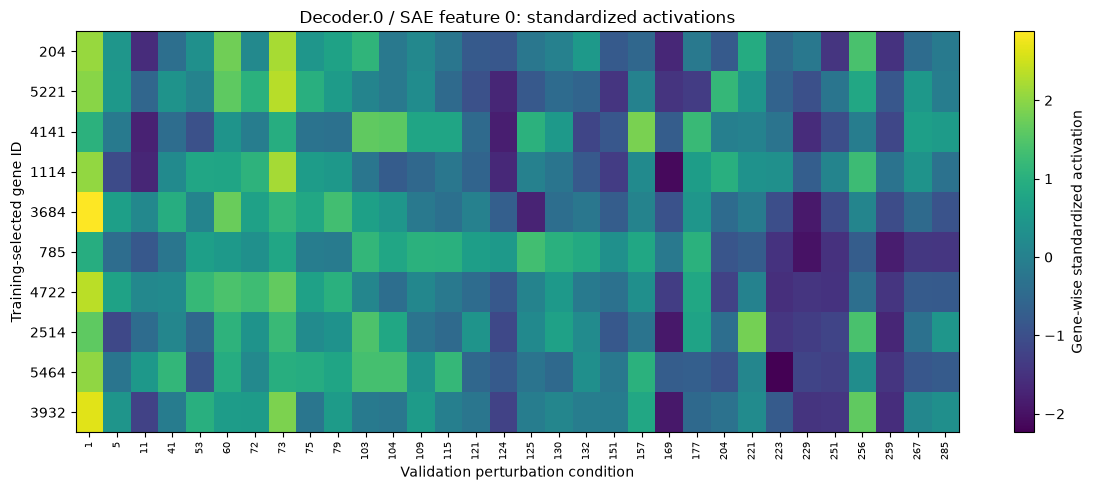


Robustness diagnostics completed.
No files modified.


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Reuse the previously computed activation matrix
# --------------------------------------------------

B = np.asarray(
    A[:, :len(top_genes)],
    dtype=np.float64
)

n_conditions, n_genes = B.shape

assert B.shape == (32, 10)
assert np.isfinite(B).all()

def common_fraction(matrix):
    centered = matrix - matrix.mean(
        axis=0, keepdims=True
    )

    total = np.sum(centered ** 2)

    if total <= 0:
        return np.nan

    shared = matrix.shape[1] * np.sum(
        centered.mean(axis=1) ** 2
    )

    return float(shared / total)


observed = common_fraction(B)

print("Original common fraction:",
      f"{100 * observed:.3f}%")


# --------------------------------------------------
# 2. Leave-one-gene-out robustness
# --------------------------------------------------

gene_loo = np.array([
    common_fraction(np.delete(B, j, axis=1))
    for j in range(n_genes)
])

print("\n=== LEAVE-ONE-GENE-OUT ===")

for gene_id, value in zip(top_genes, gene_loo):
    print(
        f"Without gene {gene_id:5d}: "
        f"{100 * value:.3f}%"
    )

print(
    "Range:",
    f"{100 * gene_loo.min():.3f}% - "
    f"{100 * gene_loo.max():.3f}%"
)


# --------------------------------------------------
# 3. Leave-one-condition-out robustness
# --------------------------------------------------

condition_loo = np.array([
    common_fraction(np.delete(B, c, axis=0))
    for c in range(n_conditions)
])

print("\n=== LEAVE-ONE-CONDITION-OUT ===")

print(
    "Minimum:",
    f"{100 * condition_loo.min():.3f}%"
)

print(
    "Maximum:",
    f"{100 * condition_loo.max():.3f}%"
)

print(
    "Mean:",
    f"{100 * condition_loo.mean():.3f}%"
)


# --------------------------------------------------
# 4. Standardize each gene
# --------------------------------------------------

gene_means = B.mean(axis=0, keepdims=True)
gene_stds = B.std(axis=0, ddof=1, keepdims=True)

assert np.all(gene_stds > 1e-10)

Z = (B - gene_means) / gene_stds

standardized_fraction = common_fraction(Z)

print("\n=== STANDARDIZED ANALYSIS ===")

print(
    "Common variation:",
    f"{100 * standardized_fraction:.3f}%"
)


# --------------------------------------------------
# 5. Pairwise gene correlations
# --------------------------------------------------

correlation = np.corrcoef(Z, rowvar=False)

upper = correlation[
    np.triu_indices(n_genes, k=1)
]

print("\n=== GENE CORRELATIONS ===")

print("Gene pairs:", len(upper))
print("Mean correlation:", round(float(upper.mean()), 4))
print("Median correlation:", round(float(np.median(upper)), 4))
print("Min correlation:", round(float(upper.min()), 4))
print("Max correlation:", round(float(upper.max()), 4))


# --------------------------------------------------
# 6. Visualize standardized gene activations
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

im = ax.imshow(
    Z.T,
    aspect="auto",
    interpolation="nearest"
)

ax.set_title(
    "Decoder.0 / SAE feature 0: "
    "standardized activations"
)

ax.set_xlabel("Validation perturbation condition")
ax.set_ylabel("Training-selected gene ID")

ax.set_xticks(np.arange(n_conditions))
ax.set_xticklabels(
    [str(int(c)) for c in condition_ids],
    rotation=90,
    fontsize=7
)

ax.set_yticks(np.arange(n_genes))
ax.set_yticklabels([str(g) for g in top_genes])

fig.colorbar(
    im,
    ax=ax,
    label="Gene-wise standardized activation"
)

plt.tight_layout()
plt.show()

print("\nRobustness diagnostics completed.")
print("No files modified.")

### 5.1. Robustness Results

The original common-condition variation fraction for SAE
feature 0 in decoder.0 was 55.476%.

Removing individual genes produced fractions ranging from
53.959% to 60.886%. Removing individual perturbation
conditions produced fractions ranging from 50.964% to
56.853%.

After gene-wise standardization, the common-condition
fraction was 60.816%.

The mean pairwise correlation between the ten gene
activation profiles was 0.5646 (median: 0.5733),
with correlations ranging from 0.0593 to 0.8298.

### Interpretation

The shared variation is not entirely driven by a single
selected gene or perturbation condition. It also persists
after accounting for differences in activation scale.

However, the result is restricted to one SAE feature and
ten genes selected using the training catalog.

These findings support the robustness of the observed
cross-gene coordination, but do not establish that this
coordination is specific to the SAE feature or that it
represents a biological perturbation mechanism.

## 6. Comparison with Random Directions in PIE Representation Space

### Research question

Is the coordinated variation observed for SAE feature 0
specific to the learned SAE representation, or is similar
coordination common in the original PIE hidden states?

### Method

We compare the observed standardized common-condition
fraction with the corresponding statistic computed from
256 randomly sampled unit directions in the original
768-dimensional decoder representation space.

The same ten training-selected genes and 32 validation
conditions are used.

Each random projection is centered and standardized
separately for each gene before computing the
common-condition variance fraction.

### Limitations

Random directions provide an exploratory geometric baseline,
not a matched null model for sparse SAE features.

The genes were selected using SAE feature 0, so this
comparison is conditional on that selection.

No formal hypothesis test or biological causal inference
is performed in this diagnostic.

In [8]:
import numpy as np

# --------------------------------------------------
# 1. Original PIE representations for selected genes
# --------------------------------------------------

X_top = np.asarray(
    X[:, :len(top_genes), :],
    dtype=np.float64
)

n_conditions, n_genes, hidden_dim = X_top.shape

assert X_top.shape == (32, 10, 768)

X_centered = X_top - X_top.mean(
    axis=0, keepdims=True
)

# --------------------------------------------------
# 2. Generate random unit directions
# --------------------------------------------------

rng = np.random.default_rng(20261111)

n_directions = 256

directions = rng.standard_normal(
    (hidden_dim, n_directions)
)

directions /= np.linalg.norm(
    directions, axis=0, keepdims=True
)

# --------------------------------------------------
# 3. Project PIE representations
# --------------------------------------------------

projections = np.einsum(
    "cgd,dk->cgk",
    X_centered,
    directions,
    optimize=True
)

# --------------------------------------------------
# 4. Standardize within each gene
# --------------------------------------------------

projection_stds = projections.std(
    axis=0, ddof=1
)

valid = np.all(
    projection_stds > 1e-12,
    axis=0
)

P = projections[:, :, valid]

P = P / projection_stds[:, valid][None, :, :]

P -= P.mean(axis=0, keepdims=True)

# --------------------------------------------------
# 5. Common-condition fractions
# --------------------------------------------------

total_ss = np.sum(P**2, axis=(0, 1))

shared_ss = n_genes * np.sum(
    P.mean(axis=1)**2,
    axis=0
)

random_fractions = shared_ss / total_ss

# Recompute the SAE feature-0 statistic
B0 = np.asarray(
    A[:, :len(top_genes)],
    dtype=np.float64
)

B0_standardized = (
    B0 - B0.mean(axis=0, keepdims=True)
) / B0.std(axis=0, ddof=1, keepdims=True)

sae_fraction = common_fraction(B0_standardized)

# --------------------------------------------------
# 6. Descriptive comparison
# --------------------------------------------------

print("=== SAE FEATURE 0 ===")
print(
    "Common fraction:",
    f"{100 * sae_fraction:.3f}%"
)

print("\n=== RANDOM PIE DIRECTIONS ===")

print("Valid directions:", len(random_fractions))

print(
    "Mean:",
    f"{100 * random_fractions.mean():.3f}%"
)

print(
    "Median:",
    f"{100 * np.median(random_fractions):.3f}%"
)

print(
    "95th percentile:",
    f"{100 * np.percentile(random_fractions, 95):.3f}%"
)

print(
    "Maximum:",
    f"{100 * random_fractions.max():.3f}%"
)

print(
    "Fraction below SAE result:",
    f"{100 * np.mean(random_fractions < sae_fraction):.2f}%"
)

print("\nRead-only diagnostic completed.")

=== SAE FEATURE 0 ===
Common fraction: 60.816%

=== RANDOM PIE DIRECTIONS ===
Valid directions: 256
Mean: 53.325%
Median: 53.198%
95th percentile: 74.620%
Maximum: 87.113%
Fraction below SAE result: 69.14%

Read-only diagnostic completed.


### 6.1. Random-Direction Baseline Results

For SAE feature 0 in decoder.0, the standardized
common-condition variation fraction was 60.816%.

Across 256 random unit directions sampled from the
768-dimensional PIE representation space:

| Statistic | Value |
|---|---:|
| SAE feature 0 | 60.816% |
| Random-direction mean | 53.325% |
| Random-direction median | 53.198% |
| Random-direction 95th percentile | 74.628% |
| Random-direction maximum | 87.113% |
| Random directions below SAE | 69.14% |

### Interpretation

The SAE feature exhibits greater coordinated variation
than the average random direction, but does not stand
out near the upper tail of the random-direction distribution.

This suggests that substantial shared condition-dependent
variation is already present in the underlying PIE
representations.

The comparison is descriptive. Random linear projections
are not matched controls for nonlinear TopK SAE features,
and the gene panel was selected using the SAE training
catalog.

Consequently, these results do not establish that
SAE feature 0 uniquely captures a perturbation-specific
or biologically meaningful mechanism.

### Next analysis

Extend the comparison to multiple SAE features, selecting
features and gene panels without using their validation
responses to determine inclusion.

## 7. Multi-Feature Exploratory Comparison

### Research question

Is shared condition-dependent variation a general property
of decoder SAE features, or does it differ substantially
between features?

### Experimental design

We evaluate SAE feature 0 together with nine additional
features sampled using a fixed random seed.

Eligible features must be active in the training catalog
and have at least ten associated genes present in every
validation condition.

For each feature, its ten genes are selected from the
training catalog. SAE activations are evaluated using
32 validation perturbation conditions.

We compare the standardized common-condition variation
fraction with 64 random directions evaluated on the
same gene panel.

### Limitations

This is an exploratory pilot, not a confirmatory
significance test. The eligibility criteria restrict
the population of features being examined.

Random directions do not reproduce SAE sparsity or
feature-selection mechanisms.

No multiple-testing claims or biological causal
conclusions are made at this stage.

In [9]:
import json
import h5py
import numpy as np
import torch

# --------------------------------------------------
# 1. Select eligible SAE features
# --------------------------------------------------

catalog_path = (
    ROOT / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_train_catalog.json"
)

catalog = json.loads(catalog_path.read_text(encoding="utf-8"))

with h5py.File(h5_path, "r") as h5:
    gene_ids_all = h5["gene_ids"][:]
    condition_ids = h5["condition_indices"][:]

common = set(map(int, gene_ids_all[0]))

for row in gene_ids_all[1:]:
    common.intersection_update(map(int, row))

panels = {}

for feature in catalog["features"]:
    if feature.get("is_dead", False):
        continue

    fid = int(feature["feature_idx"])

    genes = list(dict.fromkeys(
        int(g["gene_id"])
        for g in feature.get("top_genes", [])
        if int(g["gene_id"]) in common
    ))

    if len(genes) >= 10:
        panels[fid] = genes[:10]

assert 0 in panels
assert len(panels) >= 10

rng = np.random.default_rng(20261111)

additional = rng.choice(
    [f for f in sorted(panels) if f != 0],
    size=9,
    replace=False
)

feature_ids = [0] + [int(x) for x in additional]

print("Selected features:", feature_ids)

# --------------------------------------------------
# 2. Load the union of selected gene positions
# --------------------------------------------------

all_genes = sorted(set(
    g for fid in feature_ids for g in panels[fid]
))

gene_lookup = {g: i for i, g in enumerate(all_genes)}

vectors = []

with h5py.File(h5_path, "r") as h5:
    decoder = h5["decoder"]["0"]

    for c in range(len(condition_ids)):
        mapping = {
            int(g): i
            for i, g in enumerate(gene_ids_all[c])
        }

        positions = np.array(
            [mapping[g] for g in all_genes]
        )

        order = np.argsort(positions)

        rows = decoder[
            c, positions[order].tolist(), :
        ]

        vectors.append(rows[np.argsort(order)])

H = np.stack(vectors).astype(np.float32)

print("Loaded representations:", H.shape)

# --------------------------------------------------
# 3. Encode existing representations using SAE
# --------------------------------------------------

flat = H.reshape(-1, 768)
encoded = []

with torch.inference_mode():
    for start in range(0, len(flat), 256):
        batch = flat[start:start + 256] - mean

        Z_batch, _ = sae.encode(
            torch.from_numpy(batch)
        )

        encoded.append(
            Z_batch[:, feature_ids].cpu().numpy()
        )

S = np.concatenate(encoded).reshape(
    len(condition_ids),
    len(all_genes),
    len(feature_ids)
)

# --------------------------------------------------
# 4. Prepare random-direction baseline
# --------------------------------------------------

n_random = 64

directions = rng.standard_normal((768, n_random))
directions /= np.linalg.norm(
    directions, axis=0, keepdims=True
)

H_centered = H.astype(np.float64) - H.mean(
    axis=0, keepdims=True
)

P = np.einsum(
    "cgd,dk->cgk",
    H_centered,
    directions,
    optimize=True
)

def standardized_common(matrix):
    matrix = np.asarray(matrix, dtype=np.float64)

    sd = matrix.std(axis=0, ddof=1)

    if np.any(sd <= 1e-10):
        return np.nan

    standardized = (
        matrix - matrix.mean(axis=0, keepdims=True)
    ) / sd

    return common_fraction(standardized)

# --------------------------------------------------
# 5. Compare each feature with random directions
# --------------------------------------------------

records = []

for j, fid in enumerate(feature_ids):
    indices = [gene_lookup[g] for g in panels[fid]]

    observed = standardized_common(
        S[:, indices, j]
    )

    baseline = np.array([
        standardized_common(P[:, indices, k])
        for k in range(n_random)
    ])

    baseline = baseline[np.isfinite(baseline)]

    percentile = (
        np.mean(baseline < observed) * 100
        if np.isfinite(observed) and len(baseline)
        else np.nan
    )

    records.append({
        "feature": fid,
        "observed": observed,
        "baseline_median": (
            float(np.median(baseline))
            if len(baseline) else np.nan
        ),
        "percentile": percentile
    })

# --------------------------------------------------
# 6. Display the exploratory results
# --------------------------------------------------

print("\n=== MULTI-FEATURE COMPARISON ===")

for row in records:
    print(
        f"Feature {row['feature']:4d} | "
        f"SAE: {row['observed'] * 100:6.2f}% | "
        f"Random median: "
        f"{row['baseline_median'] * 100:6.2f}% | "
        f"Percentile: {row['percentile']:6.2f}"
    )

print("\nRead-only multi-feature diagnostic completed.")

Selected features: [0, 2678, 2586, 189, 672, 1508, 3027, 2120, 240, 3021]
Loaded representations: (32, 100, 768)

=== MULTI-FEATURE COMPARISON ===
Feature    0 | SAE:  60.82% | Random median:  55.72% | Percentile:  60.94
Feature 2678 | SAE:  62.16% | Random median:  56.47% | Percentile:  64.06
Feature 2586 | SAE:  69.32% | Random median:  62.42% | Percentile:  67.19
Feature  189 | SAE:  57.76% | Random median:  64.92% | Percentile:  26.56
Feature  672 | SAE:  60.90% | Random median:  56.92% | Percentile:  54.69
Feature 1508 | SAE:  50.22% | Random median:  59.11% | Percentile:  28.12
Feature 3027 | SAE:  56.13% | Random median:  56.78% | Percentile:  45.31
Feature 2120 | SAE:    nan% | Random median:  70.11% | Percentile:    nan
Feature  240 | SAE:  51.00% | Random median:  57.13% | Percentile:  37.50
Feature 3021 | SAE:  62.00% | Random median:  64.02% | Percentile:  45.31

Read-only multi-feature diagnostic completed.


### 7.1. Multi-Feature Pilot Results

Ten SAE features from decoder.0 were evaluated using
gene panels selected from the training catalog.

For each feature, the standardized common-condition
variation fraction was compared against 64 random
directions in the original PIE representation space.

Four features exceeded the median random-direction
baseline, five fell below it, and one feature
(feature 2120) produced an undefined standardized
statistic.

The highest observed random-direction percentile
among evaluable features was 67.19%.

### Interpretation

The pilot does not demonstrate a systematic advantage
of the selected SAE features over random linear
directions under the chosen coordination statistic.

However, this statistic measures only shared
condition-dependent variation. It does not measure
biological specificity, sparsity, feature
interpretability, or causal importance.

The comparison remains exploratory because random
directions are not matched controls for TopK features.

### Methodological issue

Feature 2120 produced an undefined statistic.

This may occur when one or more selected genes
have zero or near-zero activation variance across
validation conditions.

Activation prevalence and variability must be
examined before extending the analysis.

In [10]:
import numpy as np

print("=== FEATURE ACTIVATION QUALITY CONTROL ===")

for j, fid in enumerate(feature_ids):

    indices = [
        gene_lookup[g]
        for g in panels[fid]
    ]

    M = np.asarray(
        S[:, indices, j],
        dtype=np.float64
    )

    stds = M.std(axis=0, ddof=1)

    firing_counts = np.sum(M > 1e-8, axis=0)

    zero_variance = int(
        np.sum(stds <= 1e-10)
    )

    print(
        f"Feature {fid:4d} | "
        f"Zero-variance genes: {zero_variance}/10 | "
        f"Firing counts: "
        f"{firing_counts.min():2d}-{firing_counts.max():2d}/32"
    )

    if fid == 2120:

        print("\nFeature 2120 details:")

        for gene_id, sd, count in zip(
            panels[fid],
            stds,
            firing_counts
        ):
            print(
                f"  Gene {gene_id:5d} | "
                f"std={sd:.6f} | "
                f"active={count}/32"
            )

print("\nRead-only quality control completed.")

=== FEATURE ACTIVATION QUALITY CONTROL ===
Feature    0 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature 2678 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature 2586 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature  189 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature  672 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature 1508 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature 3027 | Zero-variance genes: 0/10 | Firing counts: 32-32/32
Feature 2120 | Zero-variance genes: 1/10 | Firing counts:  0- 6/32

Feature 2120 details:
  Gene  4773 | std=1.117967 | active=4/32
  Gene  6061 | std=0.000000 | active=0/32
  Gene   680 | std=0.857008 | active=1/32
  Gene  1342 | std=0.892741 | active=3/32
  Gene  3019 | std=1.379270 | active=6/32
  Gene  3430 | std=1.101574 | active=4/32
  Gene   994 | std=0.528211 | active=1/32
  Gene  4986 | std=1.139575 | active=3/32
  Gene  4680 | std=0.967564 | active=3/32
  Gene  1695 | std=0

### 7.2. Feature Activation Quality Control

The activation profiles of the ten selected SAE features
were examined across 32 validation perturbation conditions.

Nine features activated on all ten training-selected genes
in every validation condition.

Feature 2120 showed substantially lower activation
prevalence, with individual genes activating the feature
in only 0 to 6 conditions.

Gene 6061 exhibited zero activation in all 32 conditions,
resulting in zero variance and an undefined standardized
common-condition statistic.

### Interpretation

The selected SAE features exhibit heterogeneous
activation prevalence.

The random-direction comparison is not directly
applicable to feature 2120 under the current
standardization procedure.

This observation motivates a separate analysis of
feature activation prevalence and train-validation
stability before applying broader statistical tests.

The results are restricted to training-selected
gene panels and should not be generalized to all
output genes.

## 8. Train-Validation Stability of Feature Activation

### Research question

Do SAE features maintain similar gene-specific activation
frequencies across training and validation perturbation
conditions?

### Method

For each selected feature, we compare the number of
supporting training conditions recorded in the feature
catalog with the observed firing frequency on validation.

The same ten training-selected genes are used for
each feature.

### Interpretation

Large differences in activation prevalence may indicate
condition-dependent changes in feature activity.

However, training and validation contain different
perturbation conditions. Differences in prevalence do
not automatically imply model instability or biological
perturbation sensitivity.

This analysis is exploratory and does not involve
hypothesis testing or multiple-comparison claims.

In [11]:
import json
import numpy as np

# --------------------------------------------------
# 1. Load training feature catalog
# --------------------------------------------------

train_catalog_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_train_catalog.json"
)

train_catalog = json.loads(
    train_catalog_path.read_text(encoding="utf-8")
)

train_features = {
    int(feature["feature_idx"]): feature
    for feature in train_catalog["features"]
}

# --------------------------------------------------
# 2. Compare training and validation frequencies
# --------------------------------------------------

print("=== TRAIN-VALIDATION ACTIVATION STABILITY ===")

for j, fid in enumerate(feature_ids):

    feature = train_features[fid]

    train_genes = {
        int(g["gene_id"]): g
        for g in feature["top_genes"]
    }

    selected = panels[fid]

    train_counts = np.array([
        train_genes[g]["supporting_conditions"]
        for g in selected
    ], dtype=np.int64)

    train_freq = train_counts / 128

    indices = [
        gene_lookup[g]
        for g in selected
    ]

    V = S[:, indices, j]

    val_counts = np.sum(V > 1e-8, axis=0)
    val_freq = val_counts / 32

    mean_train = train_freq.mean()
    mean_val = val_freq.mean()

    mean_gap = np.mean(
        np.abs(train_freq - val_freq)
    )

    print(
        f"Feature {fid:4d} | "
        f"Train: {100 * mean_train:6.2f}% | "
        f"Val: {100 * mean_val:6.2f}% | "
        f"Mean absolute gap: {100 * mean_gap:6.2f} pp"
    )

    # Detailed inspection of sparse feature
    if fid == 2120:

        print("\nFeature 2120 — gene-level details:")

        for gene_id, tr, va in zip(
            selected,
            train_freq,
            val_freq
        ):
            print(
                f"  Gene {gene_id:5d}: "
                f"train={tr:.3f}, "
                f"validation={va:.3f}"
            )

        print()

print("\nRead-only stability analysis completed.")

=== TRAIN-VALIDATION ACTIVATION STABILITY ===
Feature    0 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature 2678 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature 2586 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature  189 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature  672 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature 1508 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature 3027 | Train: 100.00% | Val: 100.00% | Mean absolute gap:   0.00 pp
Feature 2120 | Train:  16.02% | Val:   8.12% | Mean absolute gap:   7.89 pp

Feature 2120 — gene-level details:
  Gene  4773: train=0.188, validation=0.125
  Gene  6061: train=0.117, validation=0.000
  Gene   680: train=0.148, validation=0.031
  Gene  1342: train=0.188, validation=0.094
  Gene  3019: train=0.203, validation=0.188
  Gene  3430: train=0.133, validation=0.125
  Gene   994: train=0.141, validation=0.031
  

### 8.1. Train-Validation Stability Results

Nine of the ten selected SAE features showed 100% firing
frequency for all ten training-selected genes in both
training and validation conditions.

Feature 2120 showed substantially lower mean firing
frequency:

- Training: 16.02%
- Validation: 8.12%
- Mean absolute frequency gap: 7.89 percentage points.

### Interpretation

The observed firing frequencies indicate that many
training-selected gene associations remain active
throughout the evaluated validation conditions.

However, this result is conditional on gene selection
from the training catalogs and cannot be generalized
to all output genes.

Feature 2120 exhibits substantially sparser activation,
with lower observed prevalence on validation.

Different perturbation compositions between the splits
may contribute to this difference.

These observations are descriptive and do not establish
statistical significance or biological causality.

### Conclusion of the exploratory pilot

The ten-feature pilot identified heterogeneous activation
patterns and substantial shared condition-dependent
variation.

However, random-direction comparisons did not demonstrate
a consistent advantage of SAE features under the chosen
coordination statistic.

The next stage will focus on perturbation identity,
structured statistical controls and feature-gene
associations beyond the selected gene panels.

In [12]:
from pathlib import Path
import h5py

print("=== CONDITION INDICES ===")

for filename in ("train_128.h5", "val_32.h5"):

    path = (
        ROOT
        / "data/activations/expanded_128_32"
        / filename
    )

    with h5py.File(path, "r") as h5:

        condition_ids = h5["condition_indices"][:]

        print(f"\n{filename}")
        print("Number of conditions:", len(condition_ids))
        print("First 15 IDs:", condition_ids[:15].tolist())
        print("HDF5 attributes:")

        for key, value in h5.attrs.items():
            print(f"  {key}: {value}")


print("\n=== POTENTIAL PERTURBATION METADATA ===")

keywords = (
    "condition",
    "perturb",
    "metadata",
    "provenance",
    "split",
    "manifest",
)

candidates = []

for directory in (ROOT / "results", ROOT / "data"):

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in (
            ".json", ".csv", ".tsv"
        ):
            continue

        if not any(
            word in path.name.lower()
            for word in keywords
        ):
            continue

        candidates.append(path)


print("Potential metadata files:", len(candidates))

for path in sorted(candidates)[:40]:

    print(
        path.relative_to(ROOT),
        f"({path.stat().st_size / 1024:.1f} KB)"
    )

print("\nRead-only metadata inspection completed.")

=== CONDITION INDICES ===

train_128.h5
Number of conditions: 128
First 15 IDs: [18, 96, 110, 160, 171, 194, 206, 213, 220, 231, 234, 249, 297, 319, 331]
HDF5 attributes:
  checkpoint_fold: k562
  completed_count: 128
  hidden_dim: 768
  n_conditions: 128
  seed: 42
  split: train

val_32.h5
Number of conditions: 32
First 15 IDs: [1, 5, 11, 41, 53, 60, 72, 73, 75, 79, 103, 104, 109, 115, 121]
HDF5 attributes:
  checkpoint_fold: k562
  completed_count: 32
  hidden_dim: 768
  n_conditions: 32
  seed: 42
  split: validation

=== POTENTIAL PERTURBATION METADATA ===
Potential metadata files: 3
data\biological_references\provenance.json (2.7 KB)
results\extraction_validation\extraction_manifest.json (4.6 KB)
results\sae_training\independent_sae_manifest.json (5.1 KB)

Read-only metadata inspection completed.


## 9. Perturbation Metadata and Condition Provenance

### Research objective

Identify the biological perturbations corresponding to
the condition indices stored in the PIE activation datasets.

The current HDF5 files contain 128 training and 32
validation conditions, but the condition indices alone
do not establish perturbation identities.

### Required information

- Original source of the perturbation conditions.
- Mapping between condition indices and perturbation labels.
- Relationship between the training and validation splits.
- Availability of biological metadata for each condition.

### Method

Inspect the original extraction manifest and the
condition-selection procedure in notebook 02.

No new statistical tests will be performed until the
meaning of the condition indices is established.

This inspection is read-only.

In [13]:
import json
import h5py
from pathlib import Path

# --------------------------------------------------
# 1. Inspect extraction manifest
# --------------------------------------------------

manifest_path = (
    ROOT
    / "results/extraction_validation/extraction_manifest.json"
)

print("=== EXTRACTION MANIFEST ===")

if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

with manifest_path.open(encoding="utf-8") as f:
    manifest = json.load(f)

print("Top-level fields:", list(manifest.keys()))

# Print relevant metadata without dumping large arrays

keywords = (
    "condition", "perturb", "source", "dataset",
    "path", "split", "index", "metadata",
    "checkpoint", "replogle", "provenance"
)

def inspect_metadata(obj, prefix="", depth=0):
    if depth > 4:
        return

    if isinstance(obj, dict):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else key

            if isinstance(value, dict):
                inspect_metadata(value, path, depth + 1)

            elif isinstance(value, list):
                if any(k in path.lower() for k in keywords):
                    print(f"{path}: list, length={len(value)}")
                    print("  Sample:", str(value[:5])[:300])

            elif any(k in path.lower() for k in keywords):
                print(f"{path}: {str(value)[:300]}")

inspect_metadata(manifest)

# --------------------------------------------------
# 2. Check training/validation separation
# --------------------------------------------------

data_dir = ROOT / "data/activations/expanded_128_32"

with h5py.File(data_dir / "train_128.h5", "r") as h5:
    train_ids = set(map(int, h5["condition_indices"][:]))

with h5py.File(data_dir / "val_32.h5", "r") as h5:
    val_ids = set(map(int, h5["condition_indices"][:]))

overlap = train_ids & val_ids

print("\n=== SPLIT INTEGRITY ===")

print("Training conditions:", len(train_ids))
print("Validation conditions:", len(val_ids))
print("Overlapping indices:", len(overlap))

if overlap:
    print("Overlapping values:", sorted(overlap)[:20])
else:
    print("No overlapping condition indices detected.")

print("\nRead-only provenance inspection completed.")

=== EXTRACTION MANIFEST ===
Top-level fields: ['experiment', 'created_at_utc', 'model', 'extraction', 'gene_reference', 'validation']
model.checkpoint: models\replogle_wdataset\k562\best_auprc.ckpt
model.checkpoint_sha256: b9d5a0b3943666d892a56e7a9368f7850826b3f1fe6879e63a1a590f8add7d84
extraction.datasets.train.file: data\activations\expanded_128_32\train_128.h5
extraction.datasets.train.dataset_size: 2603
extraction.datasets.train.sampling_seed: 42
extraction.datasets.train.condition_indices: list, length=128
  Sample: [18, 96, 110, 160, 171]
extraction.datasets.train.n_conditions: 128
extraction.datasets.train.file_size_bytes: 12475508777
extraction.datasets.train.hdf5_attributes.checkpoint_fold: k562
extraction.datasets.train.hdf5_attributes.completed_count: 128
extraction.datasets.train.hdf5_attributes.hidden_dim: 768
extraction.datasets.train.hdf5_attributes.n_conditions: 128
extraction.datasets.train.hdf5_attributes.seed: 42
extraction.datasets.train.hdf5_attributes.split: train

In [14]:
import json
import numpy as np
from pathlib import Path

print("=== ORIGINAL PIE DATASET METADATA ===")

reference_path = (
    ROOT
    / "results/gene_reference/gene_index_to_symbol.json"
)

reference = json.loads(
    reference_path.read_text(encoding="utf-8")
)

source = reference.get("source_metadata")

print("Source metadata path:", source)

if source is not None:
    meta_path = ROOT / source

    if meta_path.is_file():
        meta = json.loads(
            meta_path.read_text(encoding="utf-8")
        )

        print("\nMetadata fields:")
        print(list(meta.keys()))

        print("\n=== BIOLOGICAL IDENTIFIERS ===")

        for key in (
            "context_to_id",
            "pert_to_id",
            "perturbation_to_id",
        ):
            if key in meta:
                values = meta[key]
                print(f"\n{key}:")
                print("Total:", len(values))

                if isinstance(values, dict):
                    print(
                        "Examples:",
                        list(values.items())[:5]
                    )

        print("\n=== DATASET ROW ARRAYS ===")

        for name in ("ctx_ids.npy", "pert_ids.npy"):
            path = meta_path.parent / name

            if path.is_file():
                arr = np.load(
                    path,
                    mmap_mode="r",
                    allow_pickle=False
                )

                print(
                    name,
                    "shape:", arr.shape,
                    "dtype:", arr.dtype
                )
            else:
                print(name, "NOT FOUND")
    else:
        print("Metadata file not found locally.")

print("\n=== PIE DATASET IMPLEMENTATION ===")

source_file = (
    ROOT
    / "external/pie/src/pie/data/datamodule.py"
)

if source_file.is_file():
    lines = source_file.read_text(
        encoding="utf-8"
    ).splitlines()

    keywords = (
        "train_dataset",
        "val_dataset",
        "Dataset(",
        "split_dir",
    )

    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, 1)
        if any(k in line for k in keywords)
    ]

    for number, line in matches[:20]:
        print(f"Line {number}: {line[:160]}")
else:
    print("PIE datamodule.py not found.")

print("\nRead-only inspection completed.")

=== ORIGINAL PIE DATASET METADATA ===
Source metadata path: data\hf\datasets\arcinstitute\pie_replogle_nadig_essential\20c9faef76fc96fdc809871340bd93499413dfe7\preprocessed\meta.json

Metadata fields:
['format_version', 'dataset', 'genes', 'context_to_id', 'pert_to_id', 'pert_ensembl', 'pert_kind', 'control_label', 'num_rows', 'num_genes', 'num_contexts', 'num_perts', 'controls_only', 'tool_version', 'array_sha256']

=== BIOLOGICAL IDENTIFIERS ===

context_to_id:
Total: 4
Examples: [('hepg2', 0), ('jurkat', 1), ('k562', 2), ('rpe1', 3)]

pert_to_id:
Total: 1857
Examples: [('AAAS', 0), ('AAMP', 1), ('AAR2', 2), ('AARS', 3), ('AARS2', 4)]

=== DATASET ROW ARRAYS ===
ctx_ids.npy shape: (5459,) dtype: int32
pert_ids.npy shape: (5459,) dtype: int32

=== PIE DATASET IMPLEMENTATION ===
Line 83: split_dir: str
Line 246: self.train_dataset: PieDataset | None = None
Line 247: self.val_dataset: PieDataset | None = None
Line 286: split_dir = resolve_asset(self.cfg.split_dir, kind="splits")
Line 28

In [15]:
from pathlib import Path

PIE_DATA_SRC = ROOT / "external/pie/src/pie/data"

print("=== PIE DATASET INDEX MAPPING ===")

patterns = (
    "class PieDataset",
    "def __getitem__",
    "self.train_dataset =",
    "self.val_dataset =",
    "PieDataset(",
    "row_indices",
    "row_ids",
    "split_rows",
)

matches_found = 0

for path in sorted(PIE_DATA_SRC.rglob("*.py")):
    lines = path.read_text(encoding="utf-8").splitlines()

    matched_lines = [
        i for i, line in enumerate(lines)
        if any(pattern in line for pattern in patterns)
    ]

    if not matched_lines:
        continue

    print(f"\nFILE: {path.relative_to(ROOT)}")

    for i in matched_lines[:12]:
        matches_found += 1

        print(f"\n--- Line {i + 1} ---")

        start = max(0, i - 3)
        end = min(len(lines), i + 9)

        for j in range(start, end):
            print(f"{j + 1:4d}: {lines[j]}")

print("\nMatches inspected:", matches_found)
print("Read-only source inspection completed.")

=== PIE DATASET INDEX MAPPING ===

FILE: external\pie\src\pie\data\datamodule.py

--- Line 396 ---
 393:             else {(self.dirs[r.dir_index].dataset, r.context, r.perturbation) for r in rows}
 394:         )
 395:         index = self._ensure_evidence(forbidden)
 396:         return PieDataset(
 397:             self.dirs,
 398:             rows,
 399:             self.gene_union_ids,
 400:             self._lookup,
 401:             index,
 402:             self.cfg.fdr_threshold,
 403:             cast(Labels, labels),
 404:         )

--- Line 426 ---
 423:         val = load_split(split_dir / VAL_JSON)
 424:         check_disjoint({"train": train, "val": val})
 425:         self._ensure_evidence(split_pairs(val))
 426:         self.train_dataset = self.make_dataset(self._rows(train), "train")
 427:         self.val_dataset = self.make_dataset(self._rows(val), "eval")
 428: 
 429:     def _world(self) -> tuple[int, int]:
 430:         trainer = self.trainer
 431:         if tr

In [16]:
from pathlib import Path

source_path = (
    ROOT / "external/pie/src/pie/data/datamodule.py"
)

lines = source_path.read_text(
    encoding="utf-8"
).splitlines()

print("=== DATASET CONSTRUCTION ===")

patterns = {
    "Row selection": "def self_rows(",
    "Dataset construction": "def make_dataset(",
    "Training dataset": "self.train_dataset = self.make_dataset",
    "Validation dataset": "self.val_dataset = self.make_dataset",
}

for title, pattern in patterns.items():
    matches = [
        i for i, line in enumerate(lines)
        if pattern in line
    ]

    print(f"\n=== {title.upper()} ===")

    if not matches:
        print("Pattern not found")
        continue

    for i in matches[:1]:
        start = max(0, i - 3)
        end = min(
            len(lines),
            i + (30 if pattern.startswith("def ") else 5)
        )

        for j in range(start, end):
            print(f"{j + 1:4d}: {lines[j]}")

print("\n=== PIEDATASET IMPLEMENTATION ===")

data_dir = source_path.parent

for path in sorted(data_dir.rglob("*.py")):
    text = path.read_text(encoding="utf-8")

    if "class PieDataset" in text:
        print("Located in:", path.relative_to(ROOT))

        dataset_lines = text.splitlines()

        for i, line in enumerate(dataset_lines):
            if "class PieDataset" in line:
                for j in range(
                    i, min(i + 20, len(dataset_lines))
                ):
                    print(f"{j + 1:4d}: {dataset_lines[j]}")
                break

print("\nRead-only source inspection completed.")

=== DATASET CONSTRUCTION ===

=== ROW SELECTION ===
Pattern not found

=== DATASET CONSTRUCTION ===
 383:             raise ValueError(f"query keys name unknown datasets or contexts: {offenders}")
 384:         return [ref for di in sorted(per_dir) for ref in per_dir[di]]
 385: 
 386:     def make_dataset(self, rows: list[RowRef], labels: str) -> PieDataset:
 387:         """Dataset over `rows`; for eval/query rows, those rows are forbidden as evidence donors."""
 388:         if labels not in LABEL_KINDS:
 389:             raise ValueError(f"labels must be one of {LABEL_KINDS}, got {labels!r}")
 390:         forbidden: set[Pair] = (
 391:             set()
 392:             if labels == "train"
 393:             else {(self.dirs[r.dir_index].dataset, r.context, r.perturbation) for r in rows}
 394:         )
 395:         index = self._ensure_evidence(forbidden)
 396:         return PieDataset(
 397:             self.dirs,
 398:             rows,
 399:             self.gene_union_ids,


In [17]:
from pathlib import Path

source_path = (
    ROOT / "external/pie/src/pie/data/datamodule.py"
)

lines = source_path.read_text(
    encoding="utf-8"
).splitlines()

sections = {
    "Row selection and ordering": (345, 385),
    "Split construction": (408, 435),
    "PieDataset initialization": (120, 155),
}

for title, (start, end) in sections.items():
    print(f"\n=== {title.upper()} ===")

    for number in range(start, min(end, len(lines)) + 1):
        print(f"{number:4d}: {lines[number - 1]}")

print("\nRead-only inspection completed.")


=== ROW SELECTION AND ORDERING ===
 345:         src = self._gene_text
 346:         missing = [g for g in self.gene_axis if g not in src.key_to_row]
 347:         if missing:
 348:             raise KeyError(f"{len(missing)} genes missing from gene_text: {missing[:10]}")
 349:         rows = np.asarray([src.key_to_row[g] for g in self.gene_axis], dtype=np.int64)
 350:         return torch.from_numpy(np.array(src.embeddings[rows], dtype=np.float32))
 351: 
 352:     def _rows(self, split: Split) -> list[RowRef]:
 353:         per_dataset = resolve_split(split, self.dirs)
 354:         rows: list[RowRef] = []
 355:         for di, d in enumerate(self.dirs):
 356:             selected = per_dataset[d.dataset]
 357:             if selected.size == 0:
 358:                 continue
 359:             keys = d.row_keys()
 360:             for r in selected:
 361:                 context, perturbation = keys[int(r)]
 362:                 rows.append(RowRef(di, int(r), context, perturbation))

## 10. Reconstruction of Biological Condition Labels

### Objective

Recover the cell context and genetic perturbation
associated with each of the 160 extracted PIE conditions.

### Method

Reconstruct the original PIE train/validation datasets
using the pretrained checkpoint configuration.

Map each saved HDF5 condition index to the corresponding
ordered PieDataset row.

Verify dataset sizes and preserve the distinction between
local dataset indices and biological perturbation identities.

### Expected outcome

A condition-level mapping containing:

- Train or validation split
- Local dataset index
- Cell context
- Perturbation identity

This mapping is required before perturbation-specific
statistical analyses can be performed.

In [18]:
import os
import sys
import json
import h5py
from pathlib import Path
from collections import Counter

# --------------------------------------------------
# 1. Restore the original PIE configuration
# --------------------------------------------------

os.environ["PIE_DATA_ROOT"] = str(ROOT / "data")
os.environ["PIE_CACHE_DIR"] = str(ROOT / "cache")
os.environ["PIE_RUNS_ROOT"] = str(ROOT / "runs")

# Prevent unexpected Hugging Face downloads
os.environ["HF_HUB_OFFLINE"] = "1"

PIE_SRC = ROOT / "external/pie/src"

if str(PIE_SRC) not in sys.path:
    sys.path.insert(0, str(PIE_SRC))

from pie.predict import load_checkpoint
from pie.data.datamodule import PieDataModule

checkpoint_path = (
    ROOT / "models/replogle_wdataset/k562/best_auprc.ckpt"
)

assert checkpoint_path.is_file()

loaded = load_checkpoint(checkpoint_path)

dm_meta = PieDataModule(
    cfg=loaded.config.data,
    run_dir=None,
    stats=loaded.stats,
    seed=loaded.config.seed,
    evidence_source=loaded.config.data,
)

dm_meta.setup_stats(rank=0)
dm_meta.setup(stage="fit")

# --------------------------------------------------
# 2. Verify original dataset sizes
# --------------------------------------------------

reconstruction_manifest_path = (
    ROOT / "results/extraction_validation/extraction_manifest.json"
)
reconstruction_manifest = json.loads(
    reconstruction_manifest_path.read_text(encoding="utf-8")
)
recorded_splits = reconstruction_manifest["extraction"]["datasets"]

expected_train_size = int(recorded_splits["train"]["dataset_size"])
expected_val_size = int(recorded_splits["validation"]["dataset_size"])

assert len(dm_meta.train_dataset) == expected_train_size, (
    f"Train dataset size differs from extraction manifest: "
    f"{len(dm_meta.train_dataset)} vs {expected_train_size}"
)
assert len(dm_meta.val_dataset) == expected_val_size, (
    f"Validation dataset size differs from extraction manifest: "
    f"{len(dm_meta.val_dataset)} vs {expected_val_size}"
)
print("Dataset sizes verified against the extraction manifest.")

print("Original training rows:", len(dm_meta.train_dataset))
print("Original validation rows:", len(dm_meta.val_dataset))

# --------------------------------------------------
# 3. Map HDF5 indices to dataset rows
# --------------------------------------------------

data_dir = ROOT / "data/activations/expanded_128_32"

condition_metadata = []

jobs = [
    ("train", "train_128.h5", dm_meta.train_dataset),
    ("validation", "val_32.h5", dm_meta.val_dataset),
]

for split, filename, dataset in jobs:

    with h5py.File(data_dir / filename, "r") as h5:
        indices = h5["condition_indices"][:]

    recorded = recorded_splits[split]
    assert len(indices) == int(recorded["n_conditions"])
    assert len(set(map(int, indices))) == len(indices)
    assert all(0 <= int(i) < len(dataset) for i in indices)
    if "condition_indices" in recorded:
        assert list(map(int, indices)) == list(map(int, recorded["condition_indices"])), (
            f"{split} HDF5 indices differ from extraction manifest"
        )

    for index in indices:

        row = dataset.rows[int(index)]

        condition_metadata.append({
            "split": split,
            "local_index": int(index),
            "context": str(row.context),
            "perturbation": str(row.perturbation),
        })

assert len(condition_metadata) == 160

# --------------------------------------------------
# 4. Inspect results
# --------------------------------------------------

print("\n=== RECOVERED CONDITION METADATA ===")

for row in condition_metadata[:15]:
    print(row)

print("\n=== CELL CONTEXT DISTRIBUTION ===")

for split in ("train", "validation"):

    counts = Counter(
        row["context"]
        for row in condition_metadata
        if row["split"] == split
    )

    print(f"\n{split}:")
    for context, count in sorted(counts.items()):
        print(f"  {context}: {count}")

print("\n=== PERTURBATION COVERAGE ===")

print(
    "Unique perturbations:",
    len(set(r["perturbation"] for r in condition_metadata))
)

print(
    "Unique context-perturbation pairs:",
    len(set(
        (r["context"], r["perturbation"])
        for r in condition_metadata
    ))
)

print("\nMapping reconstructed in memory.")
print("No results or HDF5 files overwritten.")

d:\bio_paper\pie-sae\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset sizes verified against the extraction manifest.
Original training rows: 2603
Original validation rows: 290

=== RECOVERED CONDITION METADATA ===
{'split': 'train', 'local_index': 18, 'context': 'hepg2', 'perturbation': 'ARPC4'}
{'split': 'train', 'local_index': 96, 'context': 'hepg2', 'perturbation': 'CS'}
{'split': 'train', 'local_index': 110, 'context': 'hepg2', 'perturbation': 'DCUN1D5'}
{'split': 'train', 'local_index': 160, 'context': 'hepg2', 'perturbation': 'EIF3I'}
{'split': 'train', 'local_index': 171, 'context': 'hepg2', 'perturbation': 'EMC7'}
{'split': 'train', 'local_index': 194, 'context': 'hepg2', 'perturbation': 'FNTA'}
{'split': 'train', 'local_index': 206, 'context': 'hepg2', 'perturbation': 'GLRX5'}
{'split': 'train', 'local_index': 213, 'context': 'hepg2', 'perturbation': 'GPS1'}
{'split': 'train', 'local_index': 220, 'context': 'hepg2', 'perturbation': 'GTF2E2'}
{'split': 'train', 'local_index': 231, 'context': 'hepg2', 'perturbation': 'HDAC7'}
{'split': 't

In [19]:
import json
import h5py

print("=== DATASET SIZE DIAGNOSTICS ===")

manifest_path = (
    ROOT / "results/extraction_validation/extraction_manifest.json"
)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

data_dir = ROOT / "data/activations/expanded_128_32"

for split, filename, dataset in [
    ("train", "train_128.h5", dm_meta.train_dataset),
    ("validation", "val_32.h5", dm_meta.val_dataset),
]:
    recorded = manifest["extraction"]["datasets"][split]

    with h5py.File(data_dir / filename, "r") as h5:
        indices = h5["condition_indices"][:]

    print(f"\n=== {split.upper()} ===")

    print("Manifest dataset size:", recorded["dataset_size"])
    print("Current dataset size:", len(dataset))
    print("Current row count:", len(dataset.rows))

    print("Selected HDF5 conditions:", len(indices))
    print("Minimum index:", int(indices.min()))
    print("Maximum index:", int(indices.max()))

    print(
        "Dataset size matches manifest:",
        len(dataset) == recorded["dataset_size"]
    )

    print(
        "All selected indices in range:",
        bool((indices >= 0).all() and
             (indices < len(dataset)).all())
    )

    print("First three dataset rows:")

    for row in dataset.rows[:3]:
        print(
            "  Context:", row.context,
            "| Perturbation:", row.perturbation
        )

print("\n=== CONFIGURATION ===")

print("Data directories:", len(dm_meta.dirs))

for d in dm_meta.dirs:
    print(" ", str(d)[:200])

print("\nRead-only diagnostic completed.")

=== DATASET SIZE DIAGNOSTICS ===

=== TRAIN ===
Manifest dataset size: 2603
Current dataset size: 2603
Current row count: 2603
Selected HDF5 conditions: 128
Minimum index: 18
Maximum index: 2558
Dataset size matches manifest: True
All selected indices in range: True
First three dataset rows:
  Context: hepg2 | Perturbation: AAAS
  Context: hepg2 | Perturbation: AAR2
  Context: hepg2 | Perturbation: AARS

=== VALIDATION ===
Manifest dataset size: 290
Current dataset size: 290
Current row count: 290
Selected HDF5 conditions: 32
Minimum index: 1
Maximum index: 285
Dataset size matches manifest: True
All selected indices in range: True
First three dataset rows:
  Context: hepg2 | Perturbation: ACTR6
  Context: hepg2 | Perturbation: ALDOA
  Context: hepg2 | Perturbation: AP2M1

=== CONFIGURATION ===
Data directories: 1

Read-only diagnostic completed.


In [20]:
import json
import h5py
import pandas as pd
from collections import Counter

# --------------------------------------------------
# 1. Load recorded extraction metadata
# --------------------------------------------------

manifest_path = (
    ROOT / "results/extraction_validation/extraction_manifest.json"
)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

data_dir = ROOT / "data/activations/expanded_128_32"

jobs = [
    ("train", "train_128.h5", dm_meta.train_dataset),
    ("validation", "val_32.h5", dm_meta.val_dataset),
]

records = []

# --------------------------------------------------
# 2. Restore condition labels
# --------------------------------------------------

for split, filename, dataset in jobs:

    recorded = manifest["extraction"]["datasets"][split]

    assert len(dataset) == recorded["dataset_size"]

    with h5py.File(data_dir / filename, "r") as h5:
        indices = [
            int(x) for x in h5["condition_indices"][:]
        ]

    assert len(indices) == recorded["n_conditions"]
    assert len(set(indices)) == len(indices)
    assert all(0 <= i < len(dataset) for i in indices)

    if "condition_indices" in recorded:
        assert indices == [
            int(x) for x in recorded["condition_indices"]
        ]

    for index in indices:

        row = dataset.rows[index]

        records.append({
            "split": split,
            "local_index": index,
            "context": str(row.context),
            "perturbation": str(row.perturbation),
        })

condition_df = pd.DataFrame(records)

assert len(condition_df) == 160

# --------------------------------------------------
# 3. Inspect restored labels
# --------------------------------------------------

print("=== RESTORED CONDITIONS ===")

print(condition_df.groupby("split").size())

print("\n=== FIRST CONDITIONS ===")

print(
    condition_df.groupby("split")
    .head(8)
    .to_string(index=False)
)

# --------------------------------------------------
# 4. Cell context distribution
# --------------------------------------------------

print("\n=== CELL CONTEXT DISTRIBUTION ===")

print(
    pd.crosstab(
        condition_df["split"],
        condition_df["context"]
    )
)

# --------------------------------------------------
# 5. Perturbation coverage
# --------------------------------------------------

train = condition_df[
    condition_df["split"] == "train"
]

validation = condition_df[
    condition_df["split"] == "validation"
]

train_perts = set(train["perturbation"])
val_perts = set(validation["perturbation"])

train_pairs = set(zip(
    train["context"], train["perturbation"]
))

val_pairs = set(zip(
    validation["context"],
    validation["perturbation"]
))

print("\n=== PERTURBATION COVERAGE ===")

print("Training unique perturbations:", len(train_perts))
print("Validation unique perturbations:", len(val_perts))

print(
    "Shared perturbation identities:",
    len(train_perts & val_perts)
)

print(
    "Shared context-perturbation pairs:",
    len(train_pairs & val_pairs)
)

print("\nCondition mapping reconstructed in memory.")
print("No experimental files modified.")

=== RESTORED CONDITIONS ===
split
train         128
validation     32
dtype: int64

=== FIRST CONDITIONS ===
     split  local_index context perturbation
     train           18   hepg2        ARPC4
     train           96   hepg2           CS
     train          110   hepg2      DCUN1D5
     train          160   hepg2        EIF3I
     train          171   hepg2         EMC7
     train          194   hepg2         FNTA
     train          206   hepg2        GLRX5
     train          213   hepg2         GPS1
validation            1   hepg2        ALDOA
validation            5   hepg2     C1orf131
validation           11   hepg2        CENPN
validation           41   hepg2         MCM2
validation           53   hepg2       NUP107
validation           60   hepg2       POLR3D
validation           72   hepg2       SMNDC1
validation           73   hepg2      SNRNP27

=== CELL CONTEXT DISTRIBUTION ===
context     hepg2  jurkat  rpe1
split                          
train          32      45  

In [21]:
import pandas as pd

print("=== CELL CONTEXT DISTRIBUTION ===")

context_table = pd.crosstab(
    condition_df["context"],
    condition_df["split"]
)

print(context_table.to_string())


print("\n=== PERTURBATION COVERAGE ===")

train_df = condition_df.query("split == 'train'")
val_df = condition_df.query("split == 'validation'")

train_perts = set(train_df["perturbation"])
val_perts = set(val_df["perturbation"])

print("Unique train perturbations:", len(train_perts))
print("Unique validation perturbations:", len(val_perts))

print(
    "Shared perturbation identities:",
    len(train_perts & val_perts)
)


print("\n=== CROSS-CONTEXT REPETITION ===")

context_counts = (
    condition_df
    .groupby("perturbation")["context"]
    .nunique()
)

repeated = context_counts[context_counts > 1]

print(
    "Perturbations observed in multiple contexts:",
    len(repeated)
)

print(
    "Examples:",
    repeated.head(10).to_dict()
)


print("\n=== VALIDATION COVERAGE ===")

for context, group in val_df.groupby("context"):
    print(
        f"{context}: "
        f"{len(group)} conditions, "
        f"{group['perturbation'].nunique()} unique perturbations"
    )

print("\nRead-only analysis completed.")

=== CELL CONTEXT DISTRIBUTION ===
split    train  validation
context                   
hepg2       32          10
jurkat      45          13
rpe1        51           9

=== PERTURBATION COVERAGE ===
Unique train perturbations: 126
Unique validation perturbations: 32
Shared perturbation identities: 1

=== CROSS-CONTEXT REPETITION ===
Perturbations observed in multiple contexts: 3
Examples: {'HJURP': 2, 'MON1A': 2, 'NUP35': 2}

=== VALIDATION COVERAGE ===
hepg2: 10 conditions, 10 unique perturbations
jurkat: 13 conditions, 13 unique perturbations
rpe1: 9 conditions, 9 unique perturbations

Read-only analysis completed.


### 10.1. Reconstruction Results

Biological condition labels were reconstructed using
the original PIE dataset construction procedure.

The mapping contains 160 conditions:

- 128 training conditions.
- 32 validation conditions.

Each condition is associated with a cell context
and a genetic perturbation label.

No identical context-perturbation pairs were observed
in both selected splits.

The recovered labels establish the biological identity
of the analyzed conditions, subject to the original
dataset ordering and split configuration.

Further analysis will assess the distribution of
cell contexts and repeated perturbations before
selecting statistical tests.

### Statistical implications

Condition indices are local dataset positions rather
than biological perturbation identifiers.

Analyses must account for cell-context composition,
perturbation identity, and potential confounding.

The validation conditions have already been used
during exploratory analysis and are not an untouched
confirmatory test set.

## 11. Controlling for Cell-Context Effects

### Research question

Does the coordinated variation of SAE feature 0 persist
after accounting for differences between cell contexts?

### Motivation

The 32 validation conditions belong to three cell contexts:

- HepG2: 10 conditions
- Jurkat: 13 conditions
- RPE1: 9 conditions

Previous analyses pooled these conditions and detected
significant cross-gene coordination relative to an
independent condition-permutation null.

However, cell-context differences may contribute to
this coordination.

### Method

For each gene, subtract its mean activation within
each cell context:

$$
\widetilde{A}_{c,g}
=
A_{c,g}
-
\overline{A}_{k(c),g},
$$

where $k(c)$ denotes the cell context of condition $c$.

We then calculate the common-condition variance fraction
using these context-centered activations.

For the permutation control, condition assignments are
shuffled independently for each gene, but only within
the same cell context.

This preserves gene-specific activation distributions
within each context while disrupting cross-gene alignment.

### Limitations

The test evaluates coordination conditional on the
observed cell contexts.

It does not identify specific perturbation effects or
establish biological causality.

The validation conditions have already been used during
exploratory analysis, and the selected genes were chosen
using the training catalog.

In [22]:
import numpy as np
import h5py

# --------------------------------------------------
# 1. Align biological metadata with SAE activations
# --------------------------------------------------

validation_meta = (
    condition_df[
        condition_df["split"] == "validation"
    ]
    .reset_index(drop=True)
)

with h5py.File(
    ROOT / "data/activations/expanded_128_32/val_32.h5",
    "r"
) as h5:
    validation_ids = h5["condition_indices"][:]

assert np.array_equal(
    validation_meta["local_index"].to_numpy(),
    validation_ids
), "Metadata and activation rows are not aligned"

B = np.asarray(
    A[:, :len(top_genes)],
    dtype=np.float64
)

contexts = validation_meta["context"].to_numpy()

n_conditions, n_genes = B.shape

assert B.shape == (32, 10)
assert np.isfinite(B).all()

groups = {
    context: np.flatnonzero(contexts == context)
    for context in np.unique(contexts)
}

print("=== CELL CONTEXTS ===")

for context, indices in groups.items():
    print(context, len(indices))


# --------------------------------------------------
# 2. Original gene-centered activations
# --------------------------------------------------

C = B - B.mean(axis=0, keepdims=True)

ss_total = np.sum(C ** 2)

original_shared = (
    n_genes * np.sum(C.mean(axis=1) ** 2)
)

original_fraction = original_shared / ss_total


# --------------------------------------------------
# 3. Remove gene-specific cell-context means
# --------------------------------------------------

W = C.copy()

for indices in groups.values():
    W[indices] -= W[indices].mean(
        axis=0, keepdims=True
    )

ss_within = np.sum(W ** 2)

if ss_within <= 0:
    raise ValueError("No within-context variation")

context_component = C - W

ss_context = np.sum(context_component ** 2)

within_shared = (
    n_genes * np.sum(W.mean(axis=1) ** 2)
)

context_shared = (
    n_genes *
    np.sum(context_component.mean(axis=1) ** 2)
)

within_fraction = within_shared / ss_within

print("\n=== VARIANCE DECOMPOSITION ===")

print(
    "Original common fraction:",
    f"{100 * original_fraction:.3f}%"
)

print(
    "Context contribution to within-gene variance:",
    f"{100 * ss_context / ss_total:.3f}%"
)

print(
    "Context contribution to original shared variation:",
    f"{100 * context_shared / original_shared:.3f}%"
)

print(
    "Remaining within-context common fraction:",
    f"{100 * within_fraction:.3f}%"
)


# --------------------------------------------------
# 4. Stratified permutation test
# --------------------------------------------------

rng = np.random.default_rng(20261111)

n_permutations = 2000
null_fractions = np.empty(n_permutations)

for p in range(n_permutations):

    shuffled = np.empty_like(W)

    for j in range(n_genes):

        for indices in groups.values():
            shuffled[indices, j] = W[
                rng.permutation(indices), j
            ]

    shared = (
        n_genes *
        np.sum(shuffled.mean(axis=1) ** 2)
    )

    null_fractions[p] = shared / ss_within

p_value = (
    1 + np.count_nonzero(
        null_fractions >= within_fraction
    )
) / (n_permutations + 1)


# --------------------------------------------------
# 5. Results
# --------------------------------------------------

print("\n=== CONTEXT-STRATIFIED PERMUTATION ===")

print("Permutations:", n_permutations)

print(
    "Observed:",
    f"{100 * within_fraction:.3f}%"
)

print(
    "Null mean:",
    f"{100 * null_fractions.mean():.3f}%"
)

print(
    "Null 95th percentile:",
    f"{100 * np.percentile(null_fractions, 95):.3f}%"
)

print(
    "Empirical p-value:",
    f"{p_value:.6f}"
)

print("\nRead-only context analysis completed.")

=== CELL CONTEXTS ===
hepg2 10
jurkat 13
rpe1 9

=== VARIANCE DECOMPOSITION ===
Original common fraction: 55.476%
Context contribution to within-gene variance: 49.417%
Context contribution to original shared variation: 37.220%
Remaining within-context common fraction: 68.854%

=== CONTEXT-STRATIFIED PERMUTATION ===
Permutations: 2000
Observed: 68.854%
Null mean: 9.939%
Null 95th percentile: 14.266%
Empirical p-value: 0.000500

Read-only context analysis completed.


### 11.1. Cell-Context Control Results

The validation conditions comprised three cell contexts:

- HepG2: 10 conditions
- Jurkat: 13 conditions
- RPE1: 9 conditions

For SAE feature 0 in decoder.0, the original
common-condition variation fraction was 55.476%.

Cell-context differences accounted for 49.417%
of the total within-gene variation and 37.220%
of the original shared variation.

After subtracting gene-specific context means,
the common-condition fraction within the remaining
variation was 68.854%.

### Stratified Permutation Results

| Statistic | Value |
|---|---:|
| Observed within-context fraction | 68.854% |
| Null mean | 9.939% |
| Null 95th percentile | 14.266% |
| Permutations | 2,000 |
| Empirical p-value | 0.000500 |

### Interpretation

The coordinated variation is not fully explained
by differences in mean activation between cell
contexts.

The observed within-context coordination exceeds
the selected stratified permutation baseline.

The remaining signal may reflect perturbation-related
representation changes, shared model-level effects,
or other dependencies between conditions.

The analysis does not establish perturbation-specific
biological regulation or the causal importance of
the SAE feature.

The reported p-value is exploratory and has not
been corrected for feature selection or multiple
hypothesis testing.

### Methodological limitation

The original and context-adjusted common fractions
use different variance denominators and should not
be interpreted as directly comparable effect sizes.

Random-direction controls previously demonstrated
that substantial shared variation also exists in
the original PIE representation space.

## 12. Statistical Validation of Feature–Gene Associations

### Research objective

Evaluate whether the biological annotations of decoder
SAE features remain significant under more stringent
statistical controls.

### Background

Notebook 04 identified functional associations using
SAE feature–gene catalogs and biological annotation
databases.

The original analysis included gene-label permutation
controls and multiple-testing correction.

However, global gene-label permutations may not
adequately preserve gene-specific annotation frequency,
feature selection effects, or the structure of
overlapping functional gene sets.

### Next steps

1. Inspect existing feature-gene and annotation results.
2. Recover the original enrichment methodology.
3. Define suitable structured null models.
4. Evaluate significance and effect sizes.
5. Account for multiple comparisons.

The existing experimental outputs will be preserved.

In [23]:
import json
from pathlib import Path

FEATURE_ROOT = (
    ROOT / "results/sae_feature_analysis_independent"
)

print("=== BIOLOGICAL ANNOTATION FILES ===")

for layer in range(4):

    path = (
        FEATURE_ROOT
        / "biological_annotations"
        / f"decoder_{layer}_annotations.json"
    )

    print(f"\nDecoder layer {layer}")

    if not path.is_file():
        print("MISSING:", path)
        continue

    data = json.loads(
        path.read_text(encoding="utf-8")
    )

    print("File:", path.relative_to(ROOT))
    print("Size:", round(path.stat().st_size / 1024, 1), "KB")
    print("Root type:", type(data).__name__)

    if isinstance(data, dict):

        print("Top-level keys:", list(data.keys()))

        for key, value in data.items():

            if isinstance(value, list):
                print(
                    f"  {key}: list, length={len(value)}"
                )

                if value and isinstance(value[0], dict):
                    print(
                        "    First record fields:",
                        list(value[0].keys())[:20]
                    )

            elif isinstance(value, dict):
                print(
                    f"  {key}: dict, entries={len(value)}"
                )

                print(
                    "    Sample keys:",
                    list(value.keys())[:8]
                )

            else:
                print(
                    f"  {key}: {str(value)[:120]}"
                )

print("\nRead-only annotation inspection completed.")

=== BIOLOGICAL ANNOTATION FILES ===

Decoder layer 0
File: results\sae_feature_analysis_independent\biological_annotations\decoder_0_annotations.json
Size: 18147.7 KB
Root type: dict
Top-level keys: ['method', 'inputs', 'summary', 'significant_enrichments', 'feature_annotations', 'network_statistics', 'generated_utc']
  method: dict, entries=10
    Sample keys: ['gene_background', 'gene_background_size', 'term_filter', 'min_overlap_for_explicit_test', 'omitted_gene_set_tests', 'statistical_test', 'multiple_testing', 'fdr_alpha']
  inputs: dict, entries=7
    Sample keys: ['catalog_sha256', 'vocabulary_sha256', 'GO_BP_sha256', 'KEGG_sha256', 'Reactome_sha256', 'STRING_sha256', 'TRRUST_sha256']
  summary: dict, entries=11
    Sample keys: ['layer', 'n_features', 'n_ontology_terms', 'n_hypotheses_for_BH', 'n_explicit_gene_set_tests_with_overlap_ge_2', 'n_significant_feature_term_associations', 'n_features_with_significant_annotation', 'significant_by_source']
  significant_enrichments: li

## 12.1. Audit of the Original Enrichment Procedure

### Objective

Examine the statistical methodology and provenance of
the functional annotations produced in notebook 04.

### Questions

1. What gene universe and enrichment tests were used?
2. How were multiple comparisons corrected?
3. Which ontology databases were included?
4. Are the original gene sets available for new null models?

### Methodological considerations

Significant feature-term associations are selected results,
not the complete family of tested hypotheses.

Overlapping ontology terms and correlated gene annotations
may produce dependent statistical results.

The next analysis will investigate structured null models
that preserve relevant properties of the gene annotations.

No existing enrichment results will be modified.

In [24]:
import json
from pathlib import Path
from collections import Counter

ANNOT_DIR = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "biological_annotations"
)

# --------------------------------------------------
# 1. Inspect the original statistical methodology
# --------------------------------------------------

path = ANNOT_DIR / "decoder_0_annotations.json"

with path.open(encoding="utf-8") as f:
    data = json.load(f)

print("=== ORIGINAL ENRICHMENT METHOD ===")

for key, value in data["method"].items():

    if isinstance(value, (dict, list)):
        print(f"{key}: {type(value).__name__}")
        print("  Entries:", len(value))
        print("  Preview:", str(value)[:250])
    else:
        print(f"{key}: {value}")


# --------------------------------------------------
# 2. Inspect the hypothesis family
# --------------------------------------------------

print("\n=== STATISTICAL SUMMARY ===")

for key, value in data["summary"].items():
    if isinstance(value, (str, int, float, bool)):
        print(f"{key}: {value}")
    else:
        print(
            f"{key}: {type(value).__name__}, "
            f"length={len(value)}"
        )


# --------------------------------------------------
# 3. Count significant associations by source
# --------------------------------------------------

print("\n=== SIGNIFICANT ASSOCIATIONS ===")

records = data["significant_enrichments"]

source_counts = Counter(
    record["source"]
    for record in records
)

for source, count in sorted(source_counts.items()):
    print(f"{source}: {count}")

print("Total:", len(records))


# --------------------------------------------------
# 4. Compare all four decoder layers
# --------------------------------------------------

print("\n=== DECODER LAYER COMPARISON ===")

for layer in range(4):

    p = ANNOT_DIR / f"decoder_{layer}_annotations.json"

    with p.open(encoding="utf-8") as f:
        d = json.load(f)

    print(
        f"decoder.{layer}: "
        f"{len(d['feature_annotations'])} annotated features, "
        f"{len(d['significant_enrichments'])} "
        f"significant associations"
    )

    del d


# --------------------------------------------------
# 5. Locate original ontology resources
# --------------------------------------------------

print("\n=== POTENTIAL GENE-SET RESOURCES ===")

keywords = (
    "gene_set",
    "ontology",
    "go_bp",
    "kegg",
    "reactome",
    "trrust",
    "gmt",
)

candidates = []

for directory in (ROOT / "results", ROOT / "data"):

    if not directory.exists():
        continue

    for p in directory.rglob("*"):

        if not p.is_file():
            continue

        if p.suffix.lower() not in (
            ".json", ".csv", ".tsv", ".gmt"
        ):
            continue

        if any(k in p.name.lower() for k in keywords):
            candidates.append(p)

print("Potential resources:", len(candidates))

for p in sorted(candidates)[:30]:
    print(p.relative_to(ROOT))

print("\nRead-only enrichment audit completed.")

=== ORIGINAL ENRICHMENT METHOD ===
gene_background: full PIE decoder output vocabulary
gene_background_size: 6642
term_filter: retain 5..500 member genes after intersecting with PIE vocabulary
min_overlap_for_explicit_test: 2
omitted_gene_set_tests: assigned p=1 (conservative; exact Fisher p for one-gene overlap is not evaluated)
statistical_test: one-sided Fisher exact; vectorized equivalent hypergeometric survival function
multiple_testing: Benjamini-Hochberg across ALL gene-set/TF-term tests x 3072 features, per decoder layer
fdr_alpha: 0.05
network_metrics: descriptive STRING 700/900 undirected links and directed TRRUST edges; no network p-values
same_SAE_feature_train_validation: train catalog used; validation withheld for independent assessment

=== STATISTICAL SUMMARY ===
layer: decoder.0
n_features: 3072
n_ontology_terms: 4422
n_hypotheses_for_BH: 13584384
n_explicit_gene_set_tests_with_overlap_ge_2: 155479
n_significant_feature_term_associations: 18976
n_features_with_signific

### 12.2. Original Enrichment Audit Results

The original enrichment procedure in notebook 04
was examined using the saved decoder.0 annotations.

The analysis used the complete PIE decoder vocabulary
of 6,642 genes as the statistical background.

A total of 4,422 functional terms passed the
gene-set size filter of 5–500 genes.

For 3,072 SAE features, the full hypothesis family
contained 13,584,384 feature-term comparisons.

One-sided Fisher's exact tests were explicitly evaluated
for 155,479 comparisons with at least two overlapping
genes. Comparisons outside this subset were conservatively
assigned p = 1.

Benjamini–Hochberg correction was applied across the
complete feature-term hypothesis family within the layer.

At FDR < 0.05, the analysis reported:

- 18,976 significant feature-term associations.
- 1,694 SAE features with at least one significant annotation.

### Methodological interpretation

The original procedure accounts for multiple testing
within the defined feature-term hypothesis family.

However, significance remains conditional on the
background vocabulary, selected feature-gene sets,
gene-set annotations, and statistical assumptions.

Global gene-label permutation controls may not preserve
heterogeneous gene annotation degrees.

The next analysis will assess sensitivity to structured
null models that account for annotation-degree differences.

Significant enrichment is evidence of functional
association under the specified model, not proof of
biological regulation or causal importance.

In [25]:
import json
from pathlib import Path

REF_DIR = ROOT / "data/biological_references"

print("=== AVAILABLE BIOLOGICAL REFERENCES ===")

for path in sorted(REF_DIR.iterdir()):
    if path.is_file():
        print(
            path.name,
            f"({path.stat().st_size / 1024**2:.2f} MB)"
        )


# --------------------------------------------------
# 1. Inspect original ontology gene sets
# --------------------------------------------------

print("\n=== GENE-SET STRUCTURES ===")

gene_set_files = sorted(
    REF_DIR.glob("*gene_sets*.json")
)

print("Gene-set files found:", len(gene_set_files))

for path in gene_set_files:

    with path.open(encoding="utf-8") as f:
        resource = json.load(f)

    print(f"\nFILE: {path.name}")
    print("Root type:", type(resource).__name__)
    print("Total entries:", len(resource))

    if isinstance(resource, dict):

        for key, value in list(resource.items())[:2]:

            print("  Term:", str(key)[:120])
            print("  Value type:", type(value).__name__)

            if isinstance(value, dict):
                print(
                    "  Fields:",
                    list(value.keys())[:12]
                )

                for field, content in list(value.items())[:3]:
                    if isinstance(content, (list, tuple)):
                        print(
                            f"    {field}:",
                            content[:5]
                        )
                    else:
                        print(
                            f"    {field}:",
                            str(content)[:120]
                        )

            elif isinstance(value, list):
                print("  Sample members:", value[:5])

    elif isinstance(resource, list):

        for item in resource[:2]:
            print("  Sample record:", str(item)[:300])


# --------------------------------------------------
# 2. Inspect PIE gene vocabulary structure
# --------------------------------------------------

print("\n=== PIE GENE VOCABULARY ===")

vocab_path = (
    ROOT
    / "results/gene_reference/gene_index_to_symbol.json"
)

with vocab_path.open(encoding="utf-8") as f:
    vocab = json.load(f)

print("Root type:", type(vocab).__name__)

if isinstance(vocab, dict):

    print("Top-level keys:", list(vocab.keys())[:20])

    for key, value in vocab.items():

        if isinstance(value, dict):
            print(
                f"{key}: dictionary, "
                f"{len(value)} entries"
            )
            print("  Sample:", list(value.items())[:3])

        elif isinstance(value, list):
            print(
                f"{key}: list, "
                f"{len(value)} entries"
            )
            print("  Sample:", value[:3])

elif isinstance(vocab, list):
    print("Length:", len(vocab))
    print("Sample:", vocab[:5])


# --------------------------------------------------
# 3. Inspect SAE feature gene-set definition
# --------------------------------------------------

print("\n=== SAE FEATURE-GENE SETS ===")

catalog_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_train_catalog.json"
)

with catalog_path.open(encoding="utf-8") as f:
    catalog = json.load(f)

for feature in catalog["features"][:3]:

    print(
        "Feature:",
        feature["feature_idx"],
        "| Associated gene entries:",
        len(feature.get("top_genes", [])),
        "| Unique activated genes:",
        feature.get("n_unique_genes")
    )

    print(
        "  First genes:",
        [
            g.get("gene_name")
            for g in feature.get("top_genes", [])[:5]
        ]
    )

print("\nRead-only inspection completed.")

=== AVAILABLE BIOLOGICAL REFERENCES ===
9606.protein.info.v12.0.txt.gz (1.88 MB)
9606.protein.links.v12.0.txt.gz (79.31 MB)
GO_Biological_Process_2025.txt (1.29 MB)
go_bp_gene_sets.json (2.68 MB)
KEGG_2021_Human.txt (0.20 MB)
kegg_gene_sets.json (0.45 MB)
provenance.json (0.00 MB)
Reactome_2022.txt (0.74 MB)
reactome_gene_sets.json (1.61 MB)
string_ppi_edges.json (2.85 MB)
trrust_human.tsv (0.28 MB)

=== GENE-SET STRUCTURES ===
Gene-set files found: 3

FILE: go_bp_gene_sets.json
Root type: dict
Total entries: 5343
  Term: 'De Novo' AMP Biosynthetic Process (GO:0044208)
  Value type: list
  Sample members: ['ADSS1', 'ADSS2', 'ATIC', 'GART', 'PAICS']
  Term: 'De Novo' Post-Translational Protein Folding (GO:0051084)
  Value type: list
  Sample members: ['CCT2', 'CCT3', 'CCT4', 'CCT5', 'CCT6A']

FILE: kegg_gene_sets.json
Root type: dict
Total entries: 320
  Term: ABC transporters
  Value type: list
  Sample members: ['ABCA1', 'ABCA10', 'ABCA12', 'ABCA13', 'ABCA2']
  Term: AGE-RAGE signalin

## 12.3. Annotation-Degree Characterization

### Research question

How heterogeneous is the functional annotation degree
of genes in the PIE decoder vocabulary?

### Method

We reconstruct the GO Biological Process, KEGG and
Reactome gene sets using the original PIE gene universe
and the term-size filter of 5–500 represented genes.

For each gene, its annotation degree is defined as:

$$
d(g) = \sum_{t \in \mathcal{T}}
\mathbf{1}\{g \in t\}.
$$

The GO BP/KEGG/Reactome-only family is counted separately
from the 4,422-term family reported in notebook 04.
We expect 4,420 reconstructed terms for the restricted pilot;
the unresolved difference is explicitly documented below.

### Motivation

Genes with different annotation degrees may have
different probabilities of appearing in enriched
functional gene sets.

A structured gene-label permutation control can
preserve approximate annotation-degree classes while
randomizing gene identities.

### Limitations

Annotation degree reflects the structure of the
annotation databases, not a direct biological
measurement of gene importance.

Degree-stratified permutations will constitute a
sensitivity analysis under a particular null model,
rather than a universal correction for all potential
confounding factors.

In [26]:
import json
import numpy as np

from collections import Counter
from pathlib import Path

# --------------------------------------------------
# 1. Load the exact PIE gene universe
# --------------------------------------------------

vocab_path = (
    ROOT
    / "results/gene_reference/gene_index_to_symbol.json"
)

vocab = json.loads(vocab_path.read_text(encoding="utf-8"))

gene_universe = set(vocab["genes"])

assert len(vocab["genes"]) == 6642
assert len(gene_universe) == 6642

print("PIE gene universe:", len(gene_universe))


# --------------------------------------------------
# 2. Reconstruct filtered functional gene sets
# --------------------------------------------------

REF_DIR = ROOT / "data/biological_references"

resources = {
    "GO_BP": "go_bp_gene_sets.json",
    "KEGG": "kegg_gene_sets.json",
    "Reactome": "reactome_gene_sets.json",
}

gene_sets = {}
source_counts = {}

for source, filename in resources.items():

    path = REF_DIR / filename

    raw = json.loads(
        path.read_text(encoding="utf-8")
    )

    assert isinstance(raw, dict)

    count = 0

    for term, genes in raw.items():

        assert isinstance(genes, list)

        members = gene_universe.intersection(genes)

        if 5 <= len(members) <= 500:

            gene_sets[(source, term)] = members

            count += 1

    source_counts[source] = count


print("\n=== FILTERED GENE SETS ===")

for source, count in source_counts.items():
    print(f"{source}: {count}")

print("Total:", len(gene_sets))


# --------------------------------------------------
# 3. Verify consistency with notebook 04
# --------------------------------------------------

annotation_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "biological_annotations/decoder_0_annotations.json"
)

annotation = json.loads(
    annotation_path.read_text(encoding="utf-8")
)

expected_terms = int(
    annotation["summary"]["n_ontology_terms"]
)

print("\n=== REPRODUCIBILITY CHECK ===")

print("Expected terms:", expected_terms)
print("Reconstructed terms:", len(gene_sets))

# The reconstructed family contains GO BP, KEGG and Reactome only.
# The original 4,422-term figure includes a broader term family;
# its exact two-term difference is NOT resolved by this notebook.
RESTRICTED_ONTOLOGY_TERM_COUNT = 4420
if len(gene_sets) != RESTRICTED_ONTOLOGY_TERM_COUNT:
    raise ValueError(
        "Restricted ontology family changed: "
        f"expected {RESTRICTED_ONTOLOGY_TERM_COUNT}, found {len(gene_sets)}. "
        "Recheck the gene vocabulary and source files."
    )

if len(gene_sets) != expected_terms:
    print(
        "SCOPE NOTE: reconstructed GO BP/KEGG/Reactome-only family "
        f"({len(gene_sets)}) differs from original reported family "
        f"({expected_terms}). This is a restricted sensitivity analysis, "
        "not an exact reproduction of notebook 04."
    )
else:
    print("Original and reconstructed term counts match.")


# --------------------------------------------------
# 4. Calculate annotation degree
# --------------------------------------------------

degree = Counter({
    gene: 0 for gene in gene_universe
})

for members in gene_sets.values():
    degree.update(members)

degree_values = np.array(
    list(degree.values()),
    dtype=np.int64
)

print("\n=== ANNOTATION DEGREE DISTRIBUTION ===")

print("Genes:", len(degree_values))
print("Zero-degree genes:", int((degree_values == 0).sum()))
print("Mean:", round(float(degree_values.mean()), 2))
print("Median:", float(np.median(degree_values)))

for q in (25, 50, 75, 90, 95, 99):
    print(
        f"{q}th percentile:",
        float(np.percentile(degree_values, q))
    )

print("Maximum:", int(degree_values.max()))


# --------------------------------------------------
# 5. Inspect the highest-degree genes
# --------------------------------------------------

print("\n=== TOP ANNOTATED GENES ===")

for gene, count in degree.most_common(10):
    print(f"{gene:12s} degree={count}")


# --------------------------------------------------
# 6. Verify annotation membership counts
# --------------------------------------------------

total_memberships = sum(
    len(members)
    for members in gene_sets.values()
)

assert sum(degree.values()) == total_memberships

print("\nTotal gene-term memberships:", total_memberships)

print("\nRead-only annotation-degree analysis completed.")

PIE gene universe: 6642

=== FILTERED GENE SETS ===
GO_BP: 2838
KEGG: 286
Reactome: 1296
Total: 4420

=== REPRODUCIBILITY CHECK ===
Expected terms: 4422
Reconstructed terms: 4420
SCOPE NOTE: reconstructed GO BP/KEGG/Reactome-only family (4420) differs from original reported family (4422). This is a restricted sensitivity analysis, not an exact reproduction of notebook 04.

=== ANNOTATION DEGREE DISTRIBUTION ===
Genes: 6642
Zero-degree genes: 908
Mean: 18.4
Median: 10.0
25th percentile: 3.0
50th percentile: 10.0
75th percentile: 22.0
90th percentile: 43.0
95th percentile: 66.0
99th percentile: 146.0
Maximum: 375

=== TOP ANNOTATED GENES ===
RPS27A       degree=375
UBA52        degree=368
UBB          degree=360
UBC          degree=338
AKT1         degree=304
PRKCA        degree=300
PIK3R1       degree=296
MAPK3        degree=296
MAPK1        degree=295
PIK3CA       degree=265

Total gene-term memberships: 122232

Read-only annotation-degree analysis completed.


In [27]:
from pathlib import Path
import json

source_path = ROOT / "src/sae_biological_annotation.py"

print("=== ORIGINAL ANNOTATION IMPLEMENTATION ===")

if not source_path.is_file():
    raise FileNotFoundError(source_path)

lines = source_path.read_text(
    encoding="utf-8"
).splitlines()

keywords = (
    "n_ontology_terms",
    "TRRUST_TF",
    "min_term_size",
    "max_term_size",
    "gene_sets",
    "ontology_terms",
)

# Find relevant source-code lines
matching = [
    i for i, line in enumerate(lines)
    if any(keyword in line for keyword in keywords)
]

# Include a small amount of context
selected = set()

for i in matching:
    for j in range(max(0, i - 2), min(len(lines), i + 4)):
        selected.add(j)

print("\nRelevant source-code locations:")

previous = -2

for i in sorted(selected):
    if i != previous + 1:
        print("\n---")

    print(f"{i + 1:4d}: {lines[i]}")
    previous = i

print("\n=== ORIGINAL RESULT METADATA ===")

annotation_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "biological_annotations/decoder_0_annotations.json"
)

annotation = json.loads(
    annotation_path.read_text(encoding="utf-8")
)

summary = annotation["summary"]

print(
    "Original ontology term count:",
    summary["n_ontology_terms"]
)

print(
    "Significant by source:",
    summary.get("significant_by_source")
)

print(
    "Reconstructed GO/KEGG/Reactome count:",
    len(gene_sets)
)

print("\nRead-only inspection completed.")

=== ORIGINAL ANNOTATION IMPLEMENTATION ===

Relevant source-code locations:

---
  24: 
  25: REFERENCE_FILES = {
  26:     "GO_BP": "go_bp_gene_sets.json",
  27:     "KEGG": "kegg_gene_sets.json",
  28:     "Reactome": "reactome_gene_sets.json",
  29: }
  30: 
  31: 

---
 127:     *,
 128:     alpha: float = 0.05,
 129:     min_term_size: int = 5,
 130:     max_term_size: int = 500,
 131:     min_overlap: int = 2,
 132: ) -> dict:
 133:     """Annotate one PIE decoder layer; never runs PIE inference or SAE training.

---
 141:     if layer_index not in range(4):
 142:         raise ValueError("Expected a decoder layer in [0, 3]")
 143:     if not 0 < alpha < 1 or min_overlap < 1 or min_term_size < 1:
 144:         raise ValueError("Invalid enrichment configuration")
 145:     root = Path(project_root).resolve()
 146:     ref_dir = root / "data" / "biological_references"

---
 163:         raise ValueError("Expected training catalog; validation is held out")
 164: 
 165:     terms, ge

In [28]:
from collections import Counter

# --------------------------------------------------
# 1. Compare original significant terms
# --------------------------------------------------

print("=== ORIGINAL SIGNIFICANT TERM SOURCES ===")

significant = annotation["significant_enrichments"]

source_counts = Counter(
    record["source"] for record in significant
)

print("Significant associations by source:")

for source, count in sorted(source_counts.items()):
    print(f"  {source}: {count}")

original_terms = {
    (str(r["source"]), str(r["term"]))
    for r in significant
}

reconstructed_terms = set(gene_sets.keys())

missing = original_terms - reconstructed_terms

print("\n=== TERM COMPARISON ===")

print("Reconstructed terms:", len(reconstructed_terms))
print("Distinct significant original terms:", len(original_terms))
print("Significant terms absent from reconstruction:", len(missing))

print("\nMissing terms by source:")

for source, count in sorted(
    Counter(source for source, _ in missing).items()
):
    print(f"  {source}: {count}")

print("\nExamples of missing significant terms:")

for source, term in sorted(missing)[:10]:
    print(f"  [{source}] {term}")


# --------------------------------------------------
# 2. Locate original term construction and counting
# --------------------------------------------------

print("\n=== ORIGINAL SOURCE LOCATIONS ===")

search_tokens = (
    "n_ontology_terms",
    "TRRUST_TF",
    "term_sets",
    "all_terms",
    "ontology_terms",
)

for path in sorted((ROOT / "src").rglob("*.py")):

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if any(token in line for token in search_tokens)
    ]

    if not matches:
        continue

    print(f"\nFILE: {path.relative_to(ROOT)}")

    for i in matches[:15]:
        start = max(0, i - 2)
        end = min(len(lines), i + 3)

        print(f"\n--- Line {i + 1} ---")

        for j in range(start, end):
            print(f"{j + 1:4d}: {lines[j]}")

print("\nRead-only investigation completed.")

=== ORIGINAL SIGNIFICANT TERM SOURCES ===
Significant associations by source:
  GO_BP: 6744
  KEGG: 2938
  Reactome: 9261
  TRRUST_TF: 33

=== TERM COMPARISON ===
Reconstructed terms: 4420
Distinct significant original terms: 2915
Significant terms absent from reconstruction: 1

Missing terms by source:
  TRRUST_TF: 1

Examples of missing significant terms:
  [TRRUST_TF] curated_transcription_factors

=== ORIGINAL SOURCE LOCATIONS ===

FILE: src\sae_annotation_null.py

--- Line 46 ---
  44:     _, _, tf_names, _ = _load_networks(ref_dir, set(names_upper))
  45:     if len(tf_names) >= min_size:
  46:         terms.append({'source': 'TRRUST_TF', 'term': 'curated_transcription_factors', 'genes': tf_names})
  47:     if not terms:
  48:         raise ValueError('No annotation terms')

--- Line 173 ---
 171:     if X.shape != (3072, 6642):
 172:         raise ValueError('Unexpected catalog dimensions')
 173:     if n_terms != annotation['summary']['n_ontology_terms']:
 174:         raise V

### 12.4. Ontology Reconstruction and Analysis Scope

The reconstructed GO Biological Process, KEGG and Reactome
resources contain 4,420 eligible gene sets after filtering.

All significant GO BP, KEGG and Reactome terms reported
in the original decoder.0 analysis are represented in
the reconstructed resources.

The original analysis reported 4,422 tested terms.
One additional significant term was identified:

`TRRUST_TF: curated_transcription_factors`

The remaining discrepancy in the total hypothesis
count has not yet been resolved.

### Scope of the sensitivity analysis

The following degree-stratified controls will initially
use the explicitly reconstructed 4,420 GO BP, KEGG and
Reactome gene sets.

TRRUST is excluded from this initial analysis.

Results from this restricted ontology family must not
be presented as exact reproductions of the original
4,422-term testing procedure.

### Next objective

Characterize gene annotation degrees and construct
degree-stratified gene-label permutation controls.

In [29]:
import json
import numpy as np
from collections import Counter

# --------------------------------------------------
# 1. Define the ontology-only analysis family
# --------------------------------------------------

ontology_sources = {"GO_BP", "KEGG", "Reactome"}

ontology_sets = {
    key: members
    for key, members in gene_sets.items()
    if key[0] in ontology_sources
}

assert len(ontology_sets) == 4420
assert len(gene_universe) == 6642

# Check coverage of originally significant ontology terms
original_ontology_terms = {
    (str(r["source"]), str(r["term"]))
    for r in annotation["significant_enrichments"]
    if r["source"] in ontology_sources
}

missing_original = (
    original_ontology_terms - set(ontology_sets)
)

print("=== ONTOLOGY FAMILY ===")
print("Eligible terms:", len(ontology_sets))
print("Missing significant ontology terms:", len(missing_original))

assert not missing_original


# --------------------------------------------------
# 2. Calculate annotation degrees
# --------------------------------------------------

degree = Counter({
    gene: 0 for gene in gene_universe
})

for members in ontology_sets.values():
    degree.update(members)

degree_values = np.array(
    list(degree.values()), dtype=np.int64
)

print("\n=== ANNOTATION DEGREE ===")

print("Total genes:", len(degree_values))
print("Zero-degree genes:", int(np.sum(degree_values == 0)))
print("Mean:", round(float(degree_values.mean()), 3))
print("Median:", float(np.median(degree_values)))
print("Maximum:", int(degree_values.max()))

for q in (25, 50, 75, 90, 95, 99):
    print(
        f"Percentile {q}:",
        round(float(np.percentile(degree_values, q)), 2)
    )

print("\n=== HIGHEST-DEGREE GENES ===")

for gene, value in degree.most_common(10):
    print(f"{gene:12s} degree={value}")


# --------------------------------------------------
# 3. Construct degree strata
# --------------------------------------------------

positive = degree_values[degree_values > 0]

cutoffs = np.unique(
    np.quantile(positive, [0.2, 0.4, 0.6, 0.8])
)

gene_strata = {}

for gene, value in degree.items():
    if value == 0:
        stratum = 0
    else:
        stratum = 1 + int(
            np.searchsorted(cutoffs, value, side="right")
        )

    gene_strata[gene] = stratum

strata = {}

for gene, stratum in gene_strata.items():
    strata.setdefault(stratum, []).append(gene)


# --------------------------------------------------
# 4. Inspect strata
# --------------------------------------------------

print("\n=== ANNOTATION DEGREE STRATA ===")

print("Positive-degree cutoffs:", cutoffs.tolist())

for stratum, genes in sorted(strata.items()):
    values = [degree[g] for g in genes]

    print(
        f"Stratum {stratum}: "
        f"{len(genes)} genes | "
        f"degree range {min(values)}-{max(values)}"
    )

# Verify every gene belongs to exactly one stratum
assert sum(len(v) for v in strata.values()) == 6642

print("\nOntology-only degree analysis completed.")
print("No files modified.")

=== ONTOLOGY FAMILY ===
Eligible terms: 4420
Missing significant ontology terms: 0

=== ANNOTATION DEGREE ===
Total genes: 6642
Zero-degree genes: 908
Mean: 18.403
Median: 10.0
Maximum: 375
Percentile 25: 3.0
Percentile 50: 10.0
Percentile 75: 22.0
Percentile 90: 43.0
Percentile 95: 66.0
Percentile 99: 146.0

=== HIGHEST-DEGREE GENES ===
RPS27A       degree=375
UBA52        degree=368
UBB          degree=360
UBC          degree=338
AKT1         degree=304
PRKCA        degree=300
PIK3R1       degree=296
MAPK3        degree=296
MAPK1        degree=295
PIK3CA       degree=265

=== ANNOTATION DEGREE STRATA ===
Positive-degree cutoffs: [5.0, 10.0, 16.0, 29.0]
Stratum 0: 908 genes | degree range 0-0
Stratum 1: 1037 genes | degree range 1-4
Stratum 2: 1228 genes | degree range 5-9
Stratum 3: 1110 genes | degree range 10-15
Stratum 4: 1175 genes | degree range 16-28
Stratum 5: 1184 genes | degree range 29-375

Ontology-only degree analysis completed.
No files modified.


## 12.5. Global and Degree-Stratified Permutation Controls

### Research question

Does the strongest functional enrichment of decoder.0
SAE feature 0 remain unusual when gene annotation
degree is preserved?

### Experimental design

We use the Top-20 gene list from the training catalog.

Two null models are compared:

1. Global permutation of gene labels across the
   complete PIE decoder gene universe.

2. Degree-stratified permutation of gene labels
   within the previously defined annotation-degree strata.

For each permutation, enrichment is evaluated against
all 4,420 GO BP, KEGG and Reactome gene sets.

The test statistic is:

$$
T = -\log_{10}\left(\min_{t \in \mathcal{T}} p_t\right).
$$

The empirical null distribution accounts for searching
over the entire restricted ontology family.

### Limitations

This is an exploratory sensitivity analysis for one
previously examined SAE feature.

The 4,420-term family differs from the original
4,422-term analysis and excludes TRRUST.

The test does not correct for selecting SAE feature 0
from a larger collection of possible features.

Degree strata preserve approximate annotation-degree
classes, not exact gene degrees or biological properties.

In [30]:
import json
import numpy as np

from collections import defaultdict
from scipy.sparse import csr_matrix
from scipy.stats import hypergeom

# --------------------------------------------------
# 1. Load the original SAE feature-gene associations
# --------------------------------------------------

catalog_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_train_catalog.json"
)

catalog = json.loads(
    catalog_path.read_text(encoding="utf-8")
)

feature = next(
    f for f in catalog["features"]
    if int(f["feature_idx"]) == 0
)

selected_genes = [
    str(g["gene_name"])
    for g in feature["top_genes"][:20]
]

assert len(selected_genes) == 20
assert len(set(selected_genes)) == 20

genes = sorted(gene_universe)
gene_to_idx = {g: i for i, g in enumerate(genes)}

missing = set(selected_genes) - set(gene_to_idx)

if missing:
    raise ValueError(f"Genes missing from PIE vocabulary: {missing}")

selected_idx = np.array(
    [gene_to_idx[g] for g in selected_genes],
    dtype=np.int32
)

N = len(genes)
m = len(selected_idx)

print("PIE genes:", N)
print("Selected feature genes:", m)


# --------------------------------------------------
# 2. Build the ontology membership matrix
# --------------------------------------------------

ontology_keys = list(ontology_sets)

rows = []
cols = []

for term_idx, key in enumerate(ontology_keys):
    for gene in ontology_sets[key]:
        rows.append(term_idx)
        cols.append(gene_to_idx[gene])

M = csr_matrix(
    (
        np.ones(len(rows), dtype=np.uint8),
        (rows, cols)
    ),
    shape=(len(ontology_keys), N)
)

term_sizes = np.asarray(
    M.sum(axis=1)
).ravel().astype(np.int32)

assert M.shape == (4420, 6642)
assert np.all((term_sizes >= 5) & (term_sizes <= 500))

print("Ontology membership matrix:", M.shape)


# --------------------------------------------------
# 3. Precompute enrichment probabilities
# --------------------------------------------------

# Fisher's one-sided enrichment test is equivalent
# to the hypergeometric survival function.

p_table = np.vstack([
    hypergeom.sf(k - 1, N, term_sizes, m)
    for k in range(m + 1)
])

term_indices = np.arange(len(ontology_keys))

def enrichment_score(indices):
    overlap = np.asarray(
        M[:, indices].sum(axis=1)
    ).ravel().astype(np.int32)

    p_values = p_table[overlap, term_indices]

    best_idx = int(np.argmin(p_values))
    min_p = float(p_values[best_idx])

    score = -np.log10(max(min_p, 1e-300))

    return score, min_p, best_idx


observed_score, observed_min_p, best_idx = (
    enrichment_score(selected_idx)
)

print("\n=== OBSERVED ENRICHMENT ===")

print("Best term:", ontology_keys[best_idx])
print("Minimum raw Fisher p:", observed_min_p)
print("Observed statistic:", observed_score)


# --------------------------------------------------
# 4. Construct degree strata
# --------------------------------------------------

stratum_indices = defaultdict(list)

for idx, gene in enumerate(genes):
    stratum_indices[gene_strata[gene]].append(idx)

stratum_indices = {
    k: np.array(v, dtype=np.int32)
    for k, v in stratum_indices.items()
}

assert sum(
    len(v) for v in stratum_indices.values()
) == N

print("\nDegree strata:", len(stratum_indices))


# --------------------------------------------------
# 5. Generate permutation distributions
# --------------------------------------------------

rng = np.random.default_rng(20261111)

n_permutations = 500

global_scores = np.empty(n_permutations)
stratified_scores = np.empty(n_permutations)

for b in range(n_permutations):

    # Global label permutation
    global_mapping = rng.permutation(N)

    global_scores[b] = enrichment_score(
        global_mapping[selected_idx]
    )[0]

    # One globally consistent mapping, constrained
    # to preserve annotation-degree strata
    stratified_mapping = np.arange(
        N, dtype=np.int32
    )

    for indices in stratum_indices.values():
        stratified_mapping[indices] = (
            rng.permutation(indices)
        )

    stratified_scores[b] = enrichment_score(
        stratified_mapping[selected_idx]
    )[0]


# --------------------------------------------------
# 6. Empirical comparison
# --------------------------------------------------

def summarize_null(name, scores):
    p_empirical = (
        1 + np.count_nonzero(
            scores >= observed_score
        )
    ) / (len(scores) + 1)

    print(f"\n=== {name} ===")

    print("Null mean:", round(float(scores.mean()), 4))
    print(
        "Null 95th percentile:",
        round(float(np.percentile(scores, 95)), 4)
    )
    print(
        "Null maximum:",
        round(float(scores.max()), 4)
    )
    print(
        "Empirical p-value:",
        round(float(p_empirical), 6)
    )

summarize_null("GLOBAL NULL", global_scores)

summarize_null(
    "DEGREE-STRATIFIED NULL",
    stratified_scores
)

print("\nRead-only enrichment pilot completed.")

PIE genes: 6642
Selected feature genes: 20
Ontology membership matrix: (4420, 6642)

=== OBSERVED ENRICHMENT ===
Best term: ('GO_BP', 'Purine-Containing Compound Biosynthetic Process (GO:0072522)')
Minimum raw Fisher p: 1.7810838354067504e-07
Observed statistic: 6.749315637865427

Degree strata: 6

=== GLOBAL NULL ===
Null mean: 2.9499
Null 95th percentile: 4.0671
Null maximum: 4.8108
Empirical p-value: 0.001996

=== DEGREE-STRATIFIED NULL ===
Null mean: 2.6803
Null 95th percentile: 3.8811
Null maximum: 5.4208
Empirical p-value: 0.001996

Read-only enrichment pilot completed.


### 12.5.1. Global and Degree-Stratified Null Results

For SAE feature 0 in decoder.0, the Top-20 training-associated
genes were tested against 4,420 GO BP, KEGG and Reactome terms.

The strongest enrichment was:

**Purine-Containing Compound Biosynthetic Process (GO:0072522)**

- Minimum raw Fisher p-value: 1.78e-7
- Observed maximum-enrichment statistic: 6.7493

### Permutation results

| Statistic | Global null | Degree-stratified null |
|---|---:|---:|
| Permutations | 500 | 500 |
| Null 95th percentile | 4.0671 | 3.8811 |
| Null maximum | 4.8108 | 5.4208 |
| Empirical p-value | 0.001996 | 0.001996 |

Neither null distribution contained a statistic as large
as the observed value.

### Interpretation

The strongest functional enrichment remains unusual
under both the global and annotation-degree-stratified
gene-label permutation controls.

This suggests that annotation-degree heterogeneity
alone does not explain the observed enrichment under
the selected stratification procedure.

However, the analysis concerns one previously examined
SAE feature. It does not correct for selection across
the full feature dictionary.

The empirical p-values are limited by 500 permutations.
The restricted ontology family excludes TRRUST and is
not identical to the original annotation analysis.

These results support an exploratory functional
association, not biological or computational causality.

## 12.6. Multi-Feature Enrichment with MaxT Correction

### Research question

Do the functional enrichment signals of multiple decoder
SAE features remain unusual under global and
annotation-degree-stratified null models?

### Experimental design

We use the ten SAE features selected in the previous
exploratory pilot.

For each feature, the Top-20 training-associated genes
are tested against the same 4,420 ontology terms.

Both global and degree-stratified permutations are
applied consistently across all selected features
within each repetition.

The maximum statistic across the ten features is used
to estimate family-wise adjusted empirical p-values.

### Limitations

The selected feature panel is exploratory and includes
previously examined features.

The resulting correction covers the ten selected features,
not all 3,072 features in decoder.0 or all 14 SAE dictionaries.

The ontology family remains restricted to the reconstructed
GO BP, KEGG and Reactome terms.

In [31]:
import json
import numpy as np

# --------------------------------------------------
# 1. Recover the previously selected feature panel
# --------------------------------------------------

selected_features = [int(x) for x in feature_ids]

assert len(selected_features) == 10
assert len(set(selected_features)) == 10

catalog_path = (
    ROOT
    / "results/sae_feature_analysis_independent"
    / "feature_catalogs/decoder_0_train_catalog.json"
)

catalog = json.loads(
    catalog_path.read_text(encoding="utf-8")
)

features_by_id = {
    int(f["feature_idx"]): f
    for f in catalog["features"]
}

feature_gene_indices = []

for fid in selected_features:

    feature = features_by_id[fid]

    names = [
        str(g["gene_name"])
        for g in feature["top_genes"][:20]
    ]

    if len(names) != 20 or len(set(names)) != 20:
        raise ValueError(
            f"Feature {fid}: invalid Top-20 gene list"
        )

    if any(g not in gene_to_idx for g in names):
        raise ValueError(
            f"Feature {fid}: unknown gene symbols"
        )

    feature_gene_indices.append(
        np.array(
            [gene_to_idx[g] for g in names],
            dtype=np.int32
        )
    )

K = len(selected_features)

print("Features:", selected_features)
print("Ontology terms:", len(ontology_keys))


# --------------------------------------------------
# 2. Observed enrichment statistics
# --------------------------------------------------

observed = np.array([
    enrichment_score(indices)[0]
    for indices in feature_gene_indices
])

print("\nObserved statistics:")

for fid, score in zip(selected_features, observed):
    print(f"Feature {fid:4d}: T = {score:.4f}")


# --------------------------------------------------
# 3. Consistent permutations across all features
# --------------------------------------------------

rng = np.random.default_rng(20261112)

B_perm = 1000

null_global = np.empty((B_perm, K))
null_strat = np.empty((B_perm, K))

for b in range(B_perm):

    global_mapping = rng.permutation(N)

    strat_mapping = np.arange(
        N, dtype=np.int32
    )

    for indices in stratum_indices.values():
        strat_mapping[indices] = (
            rng.permutation(indices)
        )

    for j, indices in enumerate(feature_gene_indices):

        null_global[b, j] = enrichment_score(
            global_mapping[indices]
        )[0]

        null_strat[b, j] = enrichment_score(
            strat_mapping[indices]
        )[0]


# --------------------------------------------------
# 4. Empirical p-values and maxT correction
# --------------------------------------------------

def empirical_p(null_values, statistic):
    return (
        1 + np.count_nonzero(null_values >= statistic)
    ) / (len(null_values) + 1)


global_max = null_global.max(axis=1)
strat_max = null_strat.max(axis=1)

print("\n=== MULTI-FEATURE ENRICHMENT ===")

for j, fid in enumerate(selected_features):

    p_global = empirical_p(
        null_global[:, j], observed[j]
    )

    p_strat = empirical_p(
        null_strat[:, j], observed[j]
    )

    p_global_adj = empirical_p(
        global_max, observed[j]
    )

    p_strat_adj = empirical_p(
        strat_max, observed[j]
    )

    print(
        f"Feature {fid:4d} | "
        f"T={observed[j]:6.3f} | "
        f"Global p={p_global:.4f} | "
        f"Strat p={p_strat:.4f} | "
        f"Global maxT={p_global_adj:.4f} | "
        f"Strat maxT={p_strat_adj:.4f}"
    )

print("\n=== FAMILY-LEVEL RESULTS ===")

print(
    "Observed maximum T:",
    round(float(observed.max()), 4)
)

print(
    "Global maxT 95th percentile:",
    round(float(np.percentile(global_max, 95)), 4)
)

print(
    "Stratified maxT 95th percentile:",
    round(float(np.percentile(strat_max, 95)), 4)
)

print("\nRead-only analysis completed.")

Features: [0, 2678, 2586, 189, 672, 1508, 3027, 2120, 240, 3021]
Ontology terms: 4420

Observed statistics:
Feature    0: T = 6.7493
Feature 2678: T = 5.5583
Feature 2586: T = 5.8876
Feature  189: T = 9.4640
Feature  672: T = 6.0671
Feature 1508: T = 3.9070
Feature 3027: T = 6.7493
Feature 2120: T = 5.2711
Feature  240: T = 3.9198
Feature 3021: T = 3.7617

=== MULTI-FEATURE ENRICHMENT ===
Feature    0 | T= 6.749 | Global p=0.0010 | Strat p=0.0010 | Global maxT=0.0020 | Strat maxT=0.0030
Feature 2678 | T= 5.558 | Global p=0.0010 | Strat p=0.0060 | Global maxT=0.0210 | Strat maxT=0.0180
Feature 2586 | T= 5.888 | Global p=0.0020 | Strat p=0.0010 | Global maxT=0.0050 | Strat maxT=0.0110
Feature  189 | T= 9.464 | Global p=0.0010 | Strat p=0.0010 | Global maxT=0.0010 | Strat maxT=0.0010
Feature  672 | T= 6.067 | Global p=0.0010 | Strat p=0.0010 | Global maxT=0.0040 | Strat maxT=0.0070
Feature 1508 | T= 3.907 | Global p=0.0769 | Strat p=0.0340 | Global maxT=0.5275 | Strat maxT=0.4905
Feature 

### 12.6.1. Multi-Feature maxT Results

Ten decoder.0 SAE features were evaluated using their
Top-20 training-associated genes and 4,420 reconstructed
GO BP, KEGG and Reactome gene sets.

The analysis used 1,000 permutations for each of two
null models: global gene-label reassignment and
annotation-degree-stratified reassignment.

A common permutation was applied across all ten
features within each repetition, preserving their
gene-set overlap structure.

### Main findings

Seven of the ten features passed the 0.05 threshold
under both maxT-adjusted permutation controls:

- 0, 2678, 2586, 189, 672, 3027 and 2120.

Features 1508 and 240 did not pass the adjusted tests.
Feature 3021 had an observed statistic below feature
240 and therefore also cannot pass the same maxT tests.

Feature 189 showed the strongest observed enrichment
statistic (T = 9.464).

Feature 2120 passed both controls, although its global
maxT p-value (0.0460) was close to the 0.05 threshold.

### Interpretation

Several SAE feature-associated gene sets exhibit
functional enrichment beyond that expected under the
specified global and degree-stratified reassignment
null models.

The maxT procedure accounts for searching across the
4,420 ontology terms and the ten tested feature sets,
conditional on the fixed exploratory panel and the
permutation assumptions.

These results do not establish full-dictionary
significance, independent biological validation,
or causal importance.

### Limitations

- The feature panel was previously explored.
- The gene lists were derived from training conditions.
- Only 1,000 permutations were used.
- Degree strata preserve approximate annotation degrees.
- The restricted ontology family excludes TRRUST.
- The discrepancy between 4,420 reconstructed and
  4,422 originally reported terms remains unresolved.
- Ontology terms and SAE gene lists are highly dependent.

The next step is to examine the identities and overlaps
of the enriched terms before selecting candidates for
causal validation.

In [32]:
import numpy as np
import pandas as pd
from itertools import combinations

# --------------------------------------------------
# 1. Recover the strongest enrichment per feature
# --------------------------------------------------

records = []

for fid, indices in zip(
    selected_features,
    feature_gene_indices
):
    score, min_p, best_idx = enrichment_score(indices)

    source, term = ontology_keys[best_idx]

    overlap = int(M[best_idx, indices].sum())

    p_global_adj = (
        1 + np.count_nonzero(global_max >= score)
    ) / (len(global_max) + 1)

    p_strat_adj = (
        1 + np.count_nonzero(strat_max >= score)
    ) / (len(strat_max) + 1)

    records.append({
        "feature": fid,
        "source": source,
        "best_term": term,
        "overlap": overlap,
        "T": round(score, 4),
        "global_maxT": round(p_global_adj, 4),
        "strat_maxT": round(p_strat_adj, 4),
    })

results_df = pd.DataFrame(records)

print("=== FEATURE ENRICHMENT SUMMARY ===")
print(results_df.to_string(index=False))


# --------------------------------------------------
# 2. Check Top-20 gene-set overlap
# --------------------------------------------------

gene_panels = {
    fid: set(indices.tolist())
    for fid, indices in zip(
        selected_features,
        feature_gene_indices
    )
}

print("\n=== OVERLAPPING FEATURE GENE SETS ===")

pairs = []

for a, b in combinations(selected_features, 2):
    shared = len(gene_panels[a] & gene_panels[b])
    union = len(gene_panels[a] | gene_panels[b])

    pairs.append({
        "feature_a": a,
        "feature_b": b,
        "shared_genes": shared,
        "jaccard": shared / union,
    })

pair_df = pd.DataFrame(pairs).sort_values(
    "shared_genes",
    ascending=False
)

print(pair_df.head(10).to_string(index=False))

print("\nRead-only annotation comparison completed.")

=== FEATURE ENRICHMENT SUMMARY ===
 feature   source                                                              best_term  overlap      T  global_maxT  strat_maxT
       0    GO_BP           Purine-Containing Compound Biosynthetic Process (GO:0072522)        4 6.7493       0.0020      0.0030
    2678    GO_BP     Negative Regulation of Actin Filament Bundle Assembly (GO:0032232)        3 5.5583       0.0210      0.0180
    2586 Reactome                                     Nicotinate Metabolism R-HSA-196807        3 5.8876       0.0050      0.0110
     189 Reactome                          PKMTs Methylate Histone Lysines R-HSA-3214841        6 9.4640       0.0010      0.0010
     672     KEGG                                    Aldosterone synthesis and secretion        4 6.0671       0.0040      0.0070
    1508    GO_BP Endoplasmic Reticulum to Golgi Vesicle-Mediated Transport (GO:0006888)        4 3.9070       0.5275      0.4905
    3027    GO_BP                           Rho Protein

## 13. Summary of the Statistical Validation Pilot

### Objective

Consolidate the exploratory statistical analyses of
SAE features extracted from the pretrained PIE model.

The pilot examines three complementary questions:

1. Do SAE feature activations exhibit coordinated
   variation across biological conditions?

2. Are the observed activation patterns robust to
   gene selection, cell-context effects, and
   random-direction controls?

3. Do feature-associated gene sets retain functional
   enrichment under global and annotation-degree-
   stratified permutation null models?

### Scope

The principal enrichment analysis focuses on ten
decoder.0 SAE features, using their Top-20 gene
associations from the training catalog.

The restricted ontology family contains 4,420
GO Biological Process, KEGG, and Reactome gene sets.

Global and degree-stratified permutation controls
were evaluated using 1,000 repetitions each.

Single-step maxT adjustment accounts for searching
across the tested ontology terms and ten selected
features under the specified null models.

This is an exploratory pilot rather than a
full-dictionary or confirmatory validation study.

=== FINAL PILOT SUMMARY ===


,feature,source,best_term,overlap,T,global_p,strat_p,global_maxT,strat_maxT,passes_both
0,189,Reactome,PKMTs Methylate Histone Lysines R-HSA-3214841,6,9.463975,0.000999,0.000999,0.000999,0.000999,True
1,0,GO_BP,Purine-Containing Compound Biosynthetic Proces...,4,6.749316,0.000999,0.000999,0.001998,0.002997,True
2,3027,GO_BP,Rho Protein Signal Transduction (GO:0007266),4,6.749316,0.000999,0.000999,0.001998,0.002997,True
3,672,KEGG,Aldosterone synthesis and secretion,4,6.067107,0.000999,0.000999,0.003996,0.006993,True
4,2586,Reactome,Nicotinate Metabolism R-HSA-196807,3,5.887630,0.001998,0.000999,0.004995,0.010989,True
5,2678,GO_BP,Negative Regulation of Actin Filament Bundle A...,3,5.558307,0.000999,0.005994,0.020979,0.017982,True
6,2120,Reactome,Cell Cycle R-HSA-1640170,9,5.271065,0.006993,0.003996,0.045954,0.028971,True
7,240,GO_BP,Regulation of Cell Adhesion (GO:0030155),3,3.919812,0.077922,0.045954,0.523477,0.487512,False
8,1508,GO_BP,Endoplasmic Reticulum to Golgi Vesicle-Mediate...,4,3.907001,0.076923,0.033966,0.527473,0.490509,False
9,3021,GO_BP,Regulation of Cell Growth (GO:0001558),4,3.761728,0.124875,0.137862,0.707293,0.668332,False



=== SUMMARY STATISTICS ===
SAE features evaluated: 10
Ontology terms: 4420
Permutations per null: 1000
Features passing both maxT controls: 7
Feature IDs: [0, 2678, 2586, 189, 672, 3027, 2120]
Other features: [1508, 240, 3021]


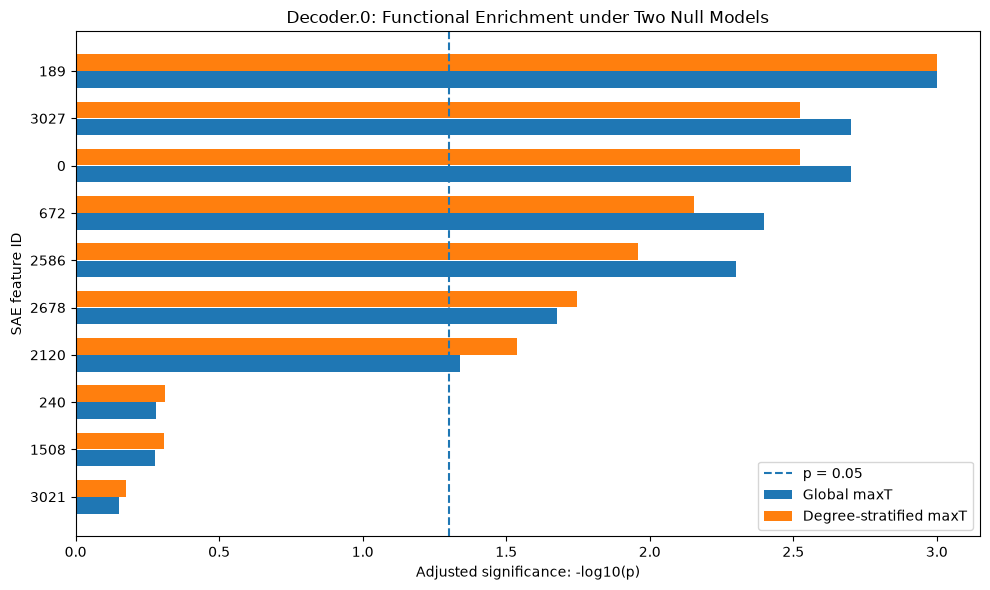


Final pilot summary completed.
No external files modified.


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Verify the completed pilot
# --------------------------------------------------

n_features = len(selected_features)
n_permutations = null_global.shape[0]

assert n_features == 10
assert len(feature_gene_indices) == n_features
assert len(ontology_keys) == 4420

assert null_global.shape == (
    n_permutations, n_features
)

assert null_strat.shape == (
    n_permutations, n_features
)

assert n_permutations == 1000

# --------------------------------------------------
# 2. Recalculate empirical and maxT p-values
# --------------------------------------------------

global_max = null_global.max(axis=1)
strat_max = null_strat.max(axis=1)

summary_rows = []

for j, fid in enumerate(selected_features):

    indices = feature_gene_indices[j]

    score, raw_p, best_idx = enrichment_score(indices)

    source, term = ontology_keys[best_idx]

    overlap = int(M[best_idx, indices].sum())

    p_global = (
        1 + np.count_nonzero(
            null_global[:, j] >= score
        )
    ) / (n_permutations + 1)

    p_strat = (
        1 + np.count_nonzero(
            null_strat[:, j] >= score
        )
    ) / (n_permutations + 1)

    p_global_adj = (
        1 + np.count_nonzero(
            global_max >= score
        )
    ) / (n_permutations + 1)

    p_strat_adj = (
        1 + np.count_nonzero(
            strat_max >= score
        )
    ) / (n_permutations + 1)

    summary_rows.append({
        "feature": int(fid),
        "source": source,
        "best_term": term,
        "overlap": overlap,
        "T": score,
        "global_p": p_global,
        "strat_p": p_strat,
        "global_maxT": p_global_adj,
        "strat_maxT": p_strat_adj,
        "passes_both": (
            p_global_adj < 0.05
            and p_strat_adj < 0.05
        ),
    })

pilot_summary = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 3. Verify statistical consistency
# --------------------------------------------------

assert np.all(
    pilot_summary["global_maxT"]
    >= pilot_summary["global_p"] - 1e-12
)

assert np.all(
    pilot_summary["strat_maxT"]
    >= pilot_summary["strat_p"] - 1e-12
)

# --------------------------------------------------
# 4. Display final summary
# --------------------------------------------------

print("=== FINAL PILOT SUMMARY ===")

display(
    pilot_summary.sort_values(
        "strat_maxT"
    ).reset_index(drop=True)
)

significant = pilot_summary[
    pilot_summary["passes_both"]
]

print("\n=== SUMMARY STATISTICS ===")

print("SAE features evaluated:", n_features)
print("Ontology terms:", len(ontology_keys))
print("Permutations per null:", n_permutations)

print(
    "Features passing both maxT controls:",
    len(significant)
)

print(
    "Feature IDs:",
    significant["feature"].tolist()
)

print(
    "Other features:",
    pilot_summary.loc[
        ~pilot_summary["passes_both"],
        "feature"
    ].tolist()
)

# --------------------------------------------------
# 5. Visualize adjusted empirical p-values
# --------------------------------------------------

plot_df = pilot_summary.sort_values(
    "T", ascending=True
)

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    y - 0.18,
    -np.log10(plot_df["global_maxT"]),
    height=0.35,
    label="Global maxT"
)

ax.barh(
    y + 0.18,
    -np.log10(plot_df["strat_maxT"]),
    height=0.35,
    label="Degree-stratified maxT"
)

ax.axvline(
    -np.log10(0.05),
    linestyle="--",
    label="p = 0.05"
)

ax.set_yticks(y)
ax.set_yticklabels(
    [str(fid) for fid in plot_df["feature"]]
)

ax.set_xlabel("Adjusted significance: -log10(p)")
ax.set_ylabel("SAE feature ID")

ax.set_title(
    "Decoder.0: Functional Enrichment "
    "under Two Null Models"
)

ax.legend()
plt.tight_layout()
plt.show()

print("\nFinal pilot summary completed.")
print("No external files modified.")

## 14. Conclusions and Research Limitations

### 14.1. Summary of findings

This notebook extended the exploratory PIE-SAE
analysis using additional statistical diagnostics.

#### Activation-level analysis

SAE feature 0 in decoder.0 exhibited coordinated
activation changes across ten training-selected
genes and 32 validation conditions.

The original common-condition variation fraction
was 55.476%, exceeding the independent
condition-permutation baseline.

The result remained robust under leave-one-gene-out
and leave-one-condition-out diagnostics.

After removing gene-specific cell-context means,
the common-condition fraction within the remaining
variation was 68.854%.

However, random linear projections of the original
PIE representations also exhibited substantial
shared variation.

Therefore, coordinated variation alone does not
establish a unique functional role for SAE feature 0.

#### Feature activation stability

The ten-feature pilot revealed heterogeneous
activation prevalence.

Nine features fired consistently on their
training-selected gene panels across validation
conditions.

Feature 2120 showed substantially sparser activation,
highlighting the need to distinguish feature
prevalence from activation magnitude and
functional enrichment.

#### Functional enrichment

Ten decoder.0 SAE features were evaluated against
4,420 reconstructed functional gene sets.

Two permutation null models were considered:

- Global gene-label reassignment.
- Annotation-degree-stratified reassignment.

Single-step maxT adjustment was applied across
the ten selected features.

Seven features passed the 0.05 threshold under
both adjusted controls:

**0, 2678, 2586, 189, 672, 3027, and 2120.**

Feature 189 exhibited the strongest observed
enrichment statistic.

The Top-20 gene sets of the selected features
were largely distinct, with only one shared gene
observed between features 1508 and 240.

These findings support exploratory functional
associations under the tested null models.

They do not demonstrate that the corresponding
SAE features implement the associated biological
processes.

### 14.2. Methodological limitations

**Exploratory selection**

The selected SAE features and validation conditions
have already been examined during earlier analyses.
The present study is not an independent
confirmatory experiment.

**Restricted feature family**

The maxT adjustment concerns ten selected
decoder.0 features, not the full dictionary
of 3,072 features or all fourteen SAE models.

**Restricted ontology family**

The reconstructed GO BP, KEGG and Reactome family
contains 4,420 terms, compared with 4,422 terms
reported in the original analysis.

The exact origin of the remaining discrepancy
has not been fully resolved.

**Permutation assumptions**

The global and degree-stratified permutation
procedures impose different exchangeability
assumptions.

Degree stratification approximately preserves
annotation-degree classes, but does not eliminate
all potential annotation biases.

**Finite Monte Carlo resolution**

With 1,000 permutations, the smallest attainable
empirical p-value is approximately 0.001.

**Biological interpretation**

Functional enrichment demonstrates statistical
association under the specified analysis.

It does not establish biological causality,
gene regulatory mechanisms, or the computational
necessity of individual SAE features.

**Perturbation structure**

The analyzed conditions span three cell contexts
and largely distinct perturbation identities.

The limited replication of identical perturbations
restricts direct estimation of perturbation-specific
effects.

### 14.3. Overall conclusion

The statistical pilot identified several
SAE-associated gene sets whose functional
enrichment remains unusual under global and
annotation-degree-stratified permutation controls.

At the same time, the activation-level experiments
demonstrated that some apparent SAE properties
are also present in random projections of the
underlying PIE representations.

These findings motivate further investigation,
but do not establish mechanistic explanations
of PIE computations.

The results should be regarded as exploratory
evidence for candidate selection rather than
confirmed biological mechanisms.

## 15. Future Work: Causal Validation

The next stage will investigate whether interventions
on selected SAE features alter the computations
and predictions of the pretrained PIE model.

### Candidate features

The following features are proposed for an
initial intervention pilot:

| Feature | Motivation |
|---|---|
| 189 | Strongest observed functional enrichment |
| 0 | Extensively characterized activation behavior |
| 2120 | Sparse activation and cell-cycle association |

These are provisional candidates.
Final selection requires additional checks of
activation prevalence, reconstruction behavior,
and intervention feasibility.

### Proposed intervention procedure

1. Obtain the hidden representation at a selected
   PIE decoder block.

2. Encode the representation using the corresponding
   trained SAE.

3. Modify or ablate a selected SAE feature.

4. Decode the intervention into the original
   representation space.

5. Resume PIE computation using the modified state.

6. Compare downstream representations and predictions
   with appropriate baseline and control interventions.

### Essential controls

Intervention experiments should account for:

- SAE reconstruction error.
- Intervention magnitude.
- Random or matched-feature controls.
- Cell-context dependence.
- Perturbation-specific effects.
- Possible off-manifold modifications.

### Scientific interpretation

Changes in PIE predictions after SAE interventions
would support claims about the computational influence
of the intervention within the model.

Such results would not, by themselves, establish
causal relationships in biological systems.

External biological validation would require
additional experimental evidence.

### Status

Statistical significance pilot: analyses and documentation completed;
full clean execution and independent methodological validation remain pending.

Full-dictionary statistical validation:
not performed.

Causal intervention experiments:
not yet performed.